# Hidden Markov Model for human activity states

This notebook builds a Hidden Markov Model from scratch with numpy. The four hidden states are standing, walking, jumping and still. The observations are the window features made in the data preparation notebook (phone accelerometer, 25 Hz, 2 second windows with 50% overlap).

Plan of the notebook:
1. Load the normalised features and turn them into time ordered sequences
2. Write the HMM functions (forward, backward, Viterbi, Baum-Welch)
3. Check the functions on a tiny example against brute force
4. Train, decode the unseen test recordings and measure the results
5. Look at the transition matrix, the emissions and the decoded sequences
6. Try other feature sets and a random start to see how much they matter

# 1. Imports and settings

In [1]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
SEED = 42
ACTIVITIES = ["standing", "walking", "jumping", "still"]
N_STATES = len(ACTIVITIES)
PALETTE = ["tab:blue", "tab:orange", "tab:red", "tab:green"]

EPSILON = 1e-4
MAX_ITER = 200
VAR_FLOOR = 0.05
PSEUDO_COUNT = 0.5

OUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
FIG_DIR = OUT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

ALL_FEATURES = ["mean_x", "mean_y", "mean_z", "log_std", "log_sma", "log_range",
                "corr_xy", "corr_xz", "corr_yz", "zero_cross_rate", "dominant_hz",
                "log_energy_low", "log_energy_high", "spectral_entropy"]
ORIENTATION = ["mean_x", "mean_y", "mean_z"]
COMPACT = ["log_energy_high", "zero_cross_rate", "dominant_hz", "spectral_entropy", "corr_xz"]

FEATURE_SETS = {
    "all 14": ALL_FEATURES,
    "motion only (11)": [f for f in ALL_FEATURES if f not in ORIENTATION],
    "compact (5)": COMPACT,
    "compact + orientation (8)": COMPACT + ORIENTATION,
}


def z_names(names):
    return ["z_" + n for n in names]

# 2. Load the normalised features

In [3]:
input_root = Path("/kaggle/input")
found = sorted(input_root.rglob("features_normalised.csv")) if input_root.exists() else []
FEATURE_FILE = found[0] if found else Path("features_normalised.csv")

data = pd.read_csv(FEATURE_FILE)
data["state"] = data["activity"].map({a: i for i, a in enumerate(ACTIVITIES)})

print("file:", FEATURE_FILE)
print("windows:", len(data))
display(data.groupby(["split", "recording", "activity"]).size().rename("windows").reset_index())

file: /kaggle/input/notebooks/divineifechukwude/hidden-markov-model-for-human-activities/features_normalised.csv
windows: 968


,split,recording,activity,windows
0,test,jumping2,jumping,36
1,test,standing2,standing,80
2,test,still2,still,164
3,test,walking2,walking,80
4,train,jumping1,jumping,24
5,train,jumping3,jumping,44
6,train,jumping4,jumping,40
7,train,jumping5,jumping,56
8,train,standing1,standing,104
9,train,standing3,standing,60


# 3. Turn the windows into sequences

An HMM needs the observations in time order. Each recording is one sequence: its windows sorted by start time. The training recordings are used to fit the model and the test recordings are never touched until the end.

One thing to be honest about: every recording has only one activity in it. So inside any single sequence the true state never changes. This means the transition matrix will learn mostly "stay in the same state", and decoding a single test recording can not really show a transition. To still check if Viterbi can switch states, I also glue the four test recordings together in a random order into one long test sequence. This glued sequence is made up by me, it is not a real recording of a person changing activity, and I label it that way everywhere.

Two more things about the sequences. The windows overlap by half inside a clip, but the clips were cut from the recording one after another, so the overlap stops at a clip edge. The table below checks the gaps between neighbouring windows.

In [4]:
def build_sequences(frame, columns):
    sequences = {}
    for name, part in frame.groupby("recording"):
        part = part.sort_values("start_s")
        sequences[name] = (part[columns].to_numpy(float), part["state"].to_numpy(int))
    return sequences


def split_sequences(columns):
    train = build_sequences(data[data["split"] == "train"], columns)
    test = build_sequences(data[data["split"] == "test"], columns)
    return train, test


train_seq, test_seq = split_sequences(z_names(ALL_FEATURES))
STITCH_ORDER = [str(n) for n in np.random.default_rng(SEED).permutation(sorted(test_seq))]

summary = []
for split_name, seqs in [("train", train_seq), ("test", test_seq)]:
    for name, (X, y) in seqs.items():
        starts = data[data["recording"] == name].sort_values("start_s")["start_s"].to_numpy()
        gaps = np.diff(starts)
        summary.append({
            "split": split_name, "recording": name, "activity": ACTIVITIES[y[0]],
            "windows": len(y), "one_activity_only": bool((y == y[0]).all()),
            "first_start_s": round(float(starts[0]), 1), "last_start_s": round(float(starts[-1]), 1),
            "gaps_of_1s": int(np.isclose(gaps, 1.0).sum()),
            "other_gaps": int((~np.isclose(gaps, 1.0)).sum()),
            "largest_gap_s": round(float(gaps.max()), 1),
        })
display(pd.DataFrame(summary).set_index(["split", "recording"]))
print("glued test order:", STITCH_ORDER)

activity  windows  one_activity_only  first_start_s  \
split recording                                                        
train jumping1    jumping       24               True            1.0   
      jumping3    jumping       44               True            1.0   
      jumping4    jumping       40               True            1.0   
      jumping5    jumping       56               True            1.0   
      standing1  standing      104               True            1.0   
      standing3  standing       60               True            1.0   
      still1        still      144               True            1.0   
      walking1    walking      136               True            1.0   
test  jumping2    jumping       36               True            1.0   
      standing2  standing       80               True            1.0   
      still2        still      164               True            1.0   
      walking2    walking       80               True            1.0   

                 last_start_s  gaps_of_1s  other_gaps  largest_gap_s  
split recording                                                       
train jumping1           29.0          18           5            2.0  
      jumping3           54.0          33          10            2.0  
      jumping4           49.0          30           9            2.0  
      jumping5           69.0          42          13            2.0  
      standing1         129.0          78          25            2.0  
      standing3          74.0          45          14            2.0  
      still1            179.0         108          35            2.0  
      walking1          169.0         102          33            2.0  
test  jumping2           44.0          27           8            2.0  
      standing2          99.0          60          19            2.0  
      still2            204.0         123          40            2.0  
      walking2           99.0          60          19            2.0

glued test order: ['walking2', 'still2', 'standing2', 'jumping2']


### 3.1 What the sequence table shows

All 12 recordings have only one activity (`one_activity_only` is True for every row). So, as I said above, inside a real sequence the state never changes, and the transition matrix can only learn "stay".

Neighbouring windows are always either 1 second apart (inside a clip) or 2 seconds apart (from one clip to the next). The largest gap is 2 seconds in every recording, so the clips follow each other with nothing missing in between. The only parts of a recording that are left out are the first and the last second, which were trimmed when the clips were made.

There are two small side effects. Inside a clip the windows overlap by half, but across the clip edge they only touch, so the HMM sees a step of 1 second sometimes and 2 seconds at other times. I do not correct for this. Also, the window that would sit across a clip edge does not exist. I think both are small compared with the difference between the activities, but they are simplifications.

The training sequences have very different lengths (24 to 144 windows), so the longer recordings, like still1 and walking1, will have more say in the learned numbers than jumping1.

# 4. The model and the algorithms

- Hidden states: standing, walking, jumping, still (4 states)
- Observation at each time step: the feature vector of one 2 second window
- Emissions: each state has a Gaussian over the features, with a diagonal covariance (every feature has its own mean and variance per state)
- Parameters: start probabilities pi, transition matrix A, and the emission means and variances

**Why these algorithms**
- The forward and backward algorithms give the probability of the data under the model and the probability of each state at each time. I compute them in log space because multiplying many small probabilities would underflow.
- Viterbi finds the single most likely state sequence. This is what turns the model into an activity classifier, so the results are judged with classification metrics: sensitivity and specificity for each activity, overall accuracy, and the confusion matrix. I chose Viterbi over picking the most likely state at each step on its own, because Viterbi gives one path that the transition matrix allows. The step by step choice can jump around.
- Baum-Welch (EM) learns the parameters from data. It repeats an E step (forward-backward to get state probabilities) and an M step (re-estimate pi, A, means and variances) until the log-likelihood changes by less than a small number epsilon. In this project the labels are known, so the parameters could also be found just by counting. I still use Baum-Welch, because it is the standard way to train an HMM and it is needed when the labels are not known. I start it from the labelled counts and later also try a random start.

**Choices I made**
- Variance floor: some features sit at their floor value for calm activities, so their variance can go close to zero and make the likelihood explode. Variances can not go below the floor.
- Pseudo count: a small count is added when estimating A and pi, so no probability is exactly zero.
- Features: the main model uses 5 features. One strength feature (several strength features are almost the same thing, r above 0.94, and a diagonal Gaussian counts them as separate evidence), two rhythm features, the spectral entropy and one correlation feature. It leaves out the orientation features, because in section 19 of the data notebook they changed between the training and test recordings. I also try the other sets later, and the main set was chosen from the training tables and not from test results.

# 5. Core functions

These are the functions the model needs: the log of the Gaussian density for every state, the forward and backward passes, and Viterbi. Everything is in log space.

In [5]:
def safe_log(x):
    """Natural log with a tiny floor (1e-300), so a zero gives a large negative number and not minus infinity."""
    return np.log(np.maximum(x, 1e-300))


def logsumexp(a, axis):
    """log(sum(exp(a))) along an axis, computed in a stable way by taking out the maximum first."""
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return np.squeeze(out, axis=axis)


def log_gaussian(X, means, variances):
    """Log density of every window under every state's diagonal Gaussian. X is (T, D), means and variances are (K, D). Returns (T, K)."""
    diff = X[:, None, :] - means[None, :, :]
    const = np.log(2 * np.pi * variances).sum(axis=1)
    quad = (diff ** 2 / variances[None, :, :]).sum(axis=2)
    return -0.5 * (const[None, :] + quad)


def forward(log_B, log_pi, log_A):
    """Forward pass in log space. Returns log_alpha (T, K): log probability of the windows up to time t, ending in state k."""
    T, K = log_B.shape
    log_alpha = np.empty((T, K))
    log_alpha[0] = log_pi + log_B[0]
    for t in range(1, T):
        log_alpha[t] = log_B[t] + logsumexp(log_alpha[t - 1][:, None] + log_A, axis=0)
    return log_alpha


def backward(log_B, log_A):
    """Backward pass in log space. Returns log_beta (T, K): log probability of the windows after time t, given state k at time t."""
    T, K = log_B.shape
    log_beta = np.zeros((T, K))
    for t in range(T - 2, -1, -1):
        log_beta[t] = logsumexp(log_A + (log_B[t + 1] + log_beta[t + 1])[None, :], axis=1)
    return log_beta


def viterbi(log_B, log_pi, log_A):
    """Most likely state path. Returns the path (T,) and its log probability."""
    T, K = log_B.shape
    delta = np.empty((T, K))
    psi = np.zeros((T, K), dtype=int)
    delta[0] = log_pi + log_B[0]
    for t in range(1, T):
        scores = delta[t - 1][:, None] + log_A
        psi[t] = scores.argmax(axis=0)
        delta[t] = scores.max(axis=0) + log_B[t]
    path = np.empty(T, dtype=int)
    path[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1][path[t + 1]]
    return path, float(delta[-1].max())

### 5.1 Check the functions against brute force

Before using these functions on real data I compare them with a slow brute force version. On a tiny random model (3 states, 5 time steps) it tries every possible state path, so there are only 243. The forward answer, the backward answer and the brute force answer for the log-likelihood should be the same, and Viterbi should find the same best path.

In [6]:
def brute_force(log_B, log_pi, log_A):
    """Slow check that tries every state path. Returns the log-likelihood and the best path. Only for tiny examples."""
    T, K = log_B.shape
    paths = list(itertools.product(range(K), repeat=T))
    scores = []
    for p in paths:
        s = log_pi[p[0]] + log_B[0, p[0]]
        for t in range(1, T):
            s += log_A[p[t - 1], p[t]] + log_B[t, p[t]]
        scores.append(s)
    scores = np.array(scores)
    return float(logsumexp(scores, axis=0)), paths[int(scores.argmax())]


rng = np.random.default_rng(SEED)
K, T = 3, 5
log_B = np.log(rng.random((T, K)))
A = rng.random((K, K))
A /= A.sum(axis=1, keepdims=True)
pi = rng.random(K)
pi /= pi.sum()
log_pi, log_A = np.log(pi), np.log(A)

log_alpha = forward(log_B, log_pi, log_A)
log_beta = backward(log_B, log_A)
ll_forward = float(logsumexp(log_alpha[-1], axis=0))
ll_backward = float(logsumexp(log_pi + log_B[0] + log_beta[0], axis=0))
path, _ = viterbi(log_B, log_pi, log_A)
ll_brute, path_brute = brute_force(log_B, log_pi, log_A)

print("log-likelihood forward :", round(ll_forward, 6))
print("log-likelihood backward:", round(ll_backward, 6))
print("log-likelihood brute   :", round(ll_brute, 6))
print("viterbi path:", path.tolist(), "| brute force path:", list(path_brute))
print("all match:", bool(np.isclose(ll_forward, ll_brute) and np.isclose(ll_backward, ll_brute) and path.tolist() == list(path_brute)))

log-likelihood forward : -2.643824
log-likelihood backward: -2.643824
log-likelihood brute   : -2.643824
viterbi path: [0, 0, 1, 2, 1] | brute force path: [0, 0, 1, 2, 1]
all match: True


The forward pass, the backward pass and the brute force search all give the same log-likelihood (-2.643824), and Viterbi finds the same best path as the brute force search ([0, 0, 1, 2, 1]). So the forward, backward and Viterbi functions are doing the right calculation. This check was on a tiny random model with made up numbers, so it does not say anything about how well the model works on the activity data. It only says that the code is correct.

# 6. The HMM class and Baum-Welch

The model is kept in one class, so the parameters and the functions that use them stay together. It has three jobs: score a sequence (log-likelihood), decode a sequence (Viterbi), and learn the parameters (Baum-Welch).

**E step.** For every sequence I run the forward and backward passes. From these I get two things for every window: the probability of being in each state (gamma), and the probability of going from one state to another between two neighbouring windows (xi). I add these up over all the sequences.

**M step.** The new parameters come from these sums, in plain words:
- the start probability of a state is how often that state is the first one
- a transition probability is the expected number of moves from state i to state j, divided by the expected number of moves out of state i
- the mean of a state is the average of the windows, where each window counts as much as its probability of being in that state
- the variance of a state is the spread around that mean, in the same weighted way

**Stopping.** The training log-likelihood is saved at every round. Training stops when it changes by less than epsilon between two rounds, or when it reaches the maximum number of rounds. `converged` says which one happened.

Two safety rules from section 4 are in the code. Variances never go below the variance floor, and a small pseudo count is added to the start and transition counts so that no probability is exactly zero. Both of these mean that the log-likelihood is not guaranteed to go up at every single round, so I check this when I train.

All the sequences are used in every round, and each one starts from its own first window, so one recording does not continue into the next.

In [7]:
class GaussianHMM:
    """Hidden Markov Model with one diagonal Gaussian per state. Learns with Baum-Welch (EM) and decodes with Viterbi."""
    def __init__(self, pi, A, means, variances, var_floor=VAR_FLOOR):
        """pi: start probabilities (K), A: transition matrix (K, K), means and variances: (K, D). Variances are never allowed below var_floor."""
        self.pi = np.array(pi, float)
        self.A = np.array(A, float)
        self.means = np.array(means, float)
        self.var_floor = var_floor
        self.variances = np.maximum(np.array(variances, float), var_floor)
        self.history = []
        self.converged = False

    def log_emission(self, X):
        """Log emission probability of every window under every state, shape (T, K)."""
        return log_gaussian(X, self.means, self.variances)

    def log_likelihood(self, X):
        """Log probability of a whole sequence under the model (forward algorithm)."""
        la = forward(self.log_emission(X), safe_log(self.pi), safe_log(self.A))
        return float(logsumexp(la[-1], axis=0))

    def decode(self, X):
        """Viterbi path of a sequence. Returns the path and its log probability."""
        return viterbi(self.log_emission(X), safe_log(self.pi), safe_log(self.A))

    def e_step(self, sequences):
        """Run forward and backward on every sequence and add up the expected counts (starts, moves, state occupancy, weighted sums) and the total log-likelihood."""
        K, D = self.means.shape
        log_pi, log_A = safe_log(self.pi), safe_log(self.A)
        stats = {"ll": 0.0, "pi": np.zeros(K), "xi": np.zeros((K, K)),
                 "g": np.zeros(K), "gx": np.zeros((K, D)), "gxx": np.zeros((K, D))}
        for X, _ in sequences:
            log_B = self.log_emission(X)
            la = forward(log_B, log_pi, log_A)
            lb = backward(log_B, log_A)
            ll = float(logsumexp(la[-1], axis=0))
            gamma = np.exp(la + lb - ll)
            log_xi = la[:-1, :, None] + log_A[None, :, :] + (log_B[1:] + lb[1:])[:, None, :] - ll
            stats["ll"] += ll
            stats["pi"] += gamma[0]
            stats["xi"] += np.exp(log_xi).sum(axis=0)
            stats["g"] += gamma.sum(axis=0)
            stats["gx"] += gamma.T @ X
            stats["gxx"] += gamma.T @ (X ** 2)
        return stats

    def m_step(self, stats):
        """New pi, A, means and variances from the expected counts. pi and A get a small pseudo count, and variances are kept at or above the floor."""
        pi = stats["pi"] + PSEUDO_COUNT
        self.pi = pi / pi.sum()
        xi = stats["xi"] + PSEUDO_COUNT
        self.A = xi / xi.sum(axis=1, keepdims=True)
        g = np.maximum(stats["g"], 1e-8)[:, None]
        self.means = stats["gx"] / g
        self.variances = np.maximum(stats["gxx"] / g - self.means ** 2, self.var_floor)

    def fit(self, sequences, epsilon=EPSILON, max_iter=MAX_ITER):
        """Baum-Welch. Repeats the E step and the M step until the log-likelihood changes by less than epsilon, or max_iter rounds. Saves the log-likelihood of every round in history and sets converged."""
        seqs = list(sequences.values())
        self.history = []
        self.converged = False
        for it in range(max_iter):
            stats = self.e_step(seqs)
            self.history.append(stats["ll"])
            self.m_step(stats)
            if it > 0 and abs(self.history[-1] - self.history[-2]) < epsilon:
                self.converged = True
                break
        return self

# 7. Starting points and evaluation helpers

**Where Baum-Welch starts.** Baum-Welch only finds a nearby best answer, so the start matters. I use two starts:
- **Supervised start (main model).** The means and variances of each state come from the labelled training windows of that activity. The start and transition probabilities come from counting in the training sequences, plus the pseudo count. Baum-Welch then refines everything without looking at the labels.
- **Random start (comparison).** The state means start at 4 training windows that are picked at random but spread apart from each other (the next one is more likely to be far from the ones already picked), with a big variance and a transition matrix that mostly stays. I try 5 random starts and keep the one with the best training log-likelihood. Here the states have no names, so after training I match each state to the activity it decodes best on the training data. With 4 states there are only 24 ways to match them, so I try all of them.

**Metrics.** Every window gets a decoded activity from Viterbi, and I compare it with the true one. For each activity I treat it as "this activity against all the others":
- sensitivity = TP / (TP + FN): of the windows that really are this activity, how many did the model find
- specificity = TN / (TN + FP): of the windows that are not this activity, how many did the model correctly leave alone
- accuracy = correct windows / all windows

The test set has 164 still windows and only 36 jumping windows, so the overall accuracy is pulled towards how well still is found. This is why I report sensitivity and specificity for each activity and not only the accuracy.

In [8]:
def check(name, condition):
    """Print ok or FAILED for a test and return True or False."""
    print("ok     " if condition else "FAILED", name)
    return bool(condition)


def decode_sequences(model, sequences, mapping=None):
    """Decode every sequence. Returns the true and the decoded labels as two long arrays. A mapping renames the states to activities."""
    truth, pred = [], []
    for X, y in sequences.values():
        path, _ = model.decode(X)
        truth.append(y)
        pred.append(path if mapping is None else mapping[path])
    return np.concatenate(truth), np.concatenate(pred)


def confusion(truth, pred):
    """Confusion matrix: rows are the true activities and columns are the decoded ones."""
    m = np.zeros((N_STATES, N_STATES), int)
    np.add.at(m, (truth, pred), 1)
    return m


def per_class_table(m):
    """TP, FN, FP, TN, sensitivity and specificity for each activity (this activity against all the others)."""
    total = m.sum()
    rows = []
    for k, name in enumerate(ACTIVITIES):
        tp = m[k, k]
        fn = m[k].sum() - tp
        fp = m[:, k].sum() - tp
        tn = total - tp - fn - fp
        rows.append({"activity": name, "windows": int(m[k].sum()), "TP": int(tp), "FN": int(fn),
                     "FP": int(fp), "TN": int(tn),
                     "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "specificity": tn / (tn + fp) if tn + fp else np.nan})
    return pd.DataFrame(rows).set_index("activity")


def accuracy(m):
    """Share of windows on the diagonal of a confusion matrix."""
    return float(np.trace(m) / m.sum())


toy_truth = np.array([0, 0, 1, 1, 2, 2, 3, 3])
toy_pred = np.array([0, 1, 1, 1, 2, 3, 3, 3])
toy_conf = confusion(toy_truth, toy_pred)
toy_table = per_class_table(toy_conf)

metric_checks = [
    check("confusion matrix counts all 8 toy windows", toy_conf.sum() == 8),
    check("confusion rows add up to the true counts", (toy_conf.sum(axis=1) == 2).all()),
    check("toy accuracy is 6/8", np.isclose(accuracy(toy_conf), 0.75)),
    check("standing sensitivity is 1/2", np.isclose(toy_table.loc["standing", "sensitivity"], 0.5)),
    check("standing specificity is 6/6", np.isclose(toy_table.loc["standing", "specificity"], 1.0)),
    check("walking sensitivity is 2/2", np.isclose(toy_table.loc["walking", "sensitivity"], 1.0)),
    check("walking specificity is 5/6", np.isclose(toy_table.loc["walking", "specificity"], 5 / 6)),
    check("TP + FN equals the window count for every activity", ((toy_table["TP"] + toy_table["FN"]) == toy_table["windows"]).all()),
    check("TP + FN + FP + TN equals 8 for every activity", (toy_table[["TP", "FN", "FP", "TN"]].sum(axis=1) == 8).all()),
]
print("all checks passed:", all(metric_checks))

ok      confusion matrix counts all 8 toy windows
ok      confusion rows add up to the true counts
ok      toy accuracy is 6/8
ok      standing sensitivity is 1/2
ok      standing specificity is 6/6
ok      walking sensitivity is 2/2
ok      walking specificity is 5/6
ok      TP + FN equals the window count for every activity
ok      TP + FN + FP + TN equals 8 for every activity
all checks passed: True


In [9]:
def stack_sequences(sequences):
    """Put all sequences together into one array of windows and one array of labels."""
    X = np.vstack([s[0] for s in sequences.values()])
    y = np.concatenate([s[1] for s in sequences.values()])
    return X, y


def init_supervised(sequences):
    """Start model from the labelled training windows: class means and variances, and start and transition probabilities from counting (plus a pseudo count)."""
    X, y = stack_sequences(sequences)
    means = np.stack([X[y == k].mean(axis=0) for k in range(N_STATES)])
    variances = np.stack([X[y == k].var(axis=0) for k in range(N_STATES)])
    moves = np.full((N_STATES, N_STATES), PSEUDO_COUNT)
    starts = np.full(N_STATES, PSEUDO_COUNT)
    for _, labels in sequences.values():
        starts[labels[0]] += 1
        np.add.at(moves, (labels[:-1], labels[1:]), 1)
    A = moves / moves.sum(axis=1, keepdims=True)
    return GaussianHMM(starts / starts.sum(), A, means, variances)


def init_random(sequences, seed):
    """Start model with 4 training windows as means (random but spread apart), a wide variance and a transition matrix that mostly stays."""
    rng = np.random.default_rng(seed)
    X, _ = stack_sequences(sequences)
    chosen = [int(rng.integers(len(X)))]
    for _ in range(N_STATES - 1):
        d = ((X[:, None, :] - X[chosen][None, :, :]) ** 2).sum(axis=2).min(axis=1)
        chosen.append(int(rng.choice(len(X), p=d / d.sum())))
    means = X[chosen]
    variances = np.tile(X.var(axis=0), (N_STATES, 1))
    A = np.full((N_STATES, N_STATES), 0.2 / (N_STATES - 1))
    np.fill_diagonal(A, 0.8)
    return GaussianHMM(np.full(N_STATES, 1 / N_STATES), A, means, variances)


def best_random_fit(sequences, n_starts):
    """Train n_starts random starts and keep the one with the best final training log-likelihood."""
    best = None
    for s in range(n_starts):
        model = init_random(sequences, SEED + s).fit(sequences)
        if best is None or model.history[-1] > best.history[-1]:
            best = model
    return best


def best_mapping(state_vs_truth):
    """Try all ways to match states to activities and keep the one with the most matching windows."""
    return np.array(max(
        itertools.permutations(range(N_STATES)),
        key=lambda p: sum(state_vs_truth[i, p[i]] for i in range(N_STATES))))


toy_rng = np.random.default_rng(SEED)
toy_centres = np.array([[0, 0, 0], [4, 0, 0], [0, 4, 0], [0, 0, 4]], float)
toy_seq = {}
for k in range(N_STATES):
    for r in range(2):
        toy_seq[f"toy{k}_{r}"] = (toy_centres[k] + 0.5 * toy_rng.standard_normal((30, 3)), np.full(30, k))

sup = init_supervised(toy_seq)
rnd_a, rnd_b = init_random(toy_seq, SEED), init_random(toy_seq, SEED)
known_map = np.array([2, 0, 3, 1])
fake_conf = np.ones((N_STATES, N_STATES), int)
fake_conf[np.arange(N_STATES), known_map] = 20
toy_model = best_random_fit(toy_seq, 3)
toy_truth2, toy_states = decode_sequences(toy_model, toy_seq)
toy_map = best_mapping(confusion(toy_states, toy_truth2))
toy_acc = accuracy(confusion(toy_truth2, toy_map[toy_states]))

start_checks = [
    check("supervised start: probabilities add up to 1", np.isclose(sup.pi.sum(), 1) and np.allclose(sup.A.sum(axis=1), 1)),
    check("supervised start: means land on the 4 toy centres", np.allclose(sup.means, toy_centres, atol=0.3)),
    check("supervised start: staying is more likely than moving", all(sup.A[i, i] > sup.A[i].sum() - sup.A[i, i] for i in range(N_STATES))),
    check("supervised start: nothing is exactly 0", (sup.A > 0).all() and (sup.pi > 0).all()),
    check("random start: same seed gives the same start", np.allclose(rnd_a.means, rnd_b.means)),
    check("random start: 4 different starting windows", len({tuple(m) for m in rnd_a.means.round(8)}) == N_STATES),
    check("random start: transition rows add up to 1", np.allclose(rnd_a.A.sum(axis=1), 1)),
    check("mapping finds a known shuffle of the states", np.array_equal(best_mapping(fake_conf), known_map)),
    check("training ran and the log-likelihood is finite", len(toy_model.history) > 0 and np.isfinite(toy_model.history).all()),
    check("training did not end worse than it started", toy_model.history[-1] >= toy_model.history[0]),
    check("trained toy model finds the 4 clusters (accuracy above 0.9)", toy_acc > 0.9),
]
print("toy training rounds:", len(toy_model.history), "| converged:", toy_model.converged, "| toy accuracy:", round(toy_acc, 3))
print("largest drop of the log-likelihood between two rounds:", round(float(max(0.0, -np.diff(toy_model.history).min())) if len(toy_model.history) > 1 else 0.0, 6))
print("all checks passed:", all(start_checks))

ok      supervised start: probabilities add up to 1
ok      supervised start: means land on the 4 toy centres
ok      supervised start: staying is more likely than moving
ok      supervised start: nothing is exactly 0
ok      random start: same seed gives the same start
ok      random start: 4 different starting windows
ok      random start: transition rows add up to 1
ok      mapping finds a known shuffle of the states
ok      training ran and the log-likelihood is finite
ok      training did not end worse than it started
ok      trained toy model finds the 4 clusters (accuracy above 0.9)
toy training rounds: 5 | converged: True | toy accuracy: 1.0
largest drop of the log-likelihood between two rounds: 0.0
all checks passed: True


### 7.1 The starting model before Baum-Welch

Before any training I look at the supervised start for the main feature set. I only decode the training recordings here, and the test recordings stay untouched until the model is trained. The checks below make sure that the numbers are valid before I train anything.

In [10]:
main_features = FEATURE_SETS["compact (5)"]
start_train, _ = split_sequences(z_names(main_features))
start_model = init_supervised(start_train)

n_windows = sum(len(s[1]) for s in start_train.values())
truth, pred = decode_sequences(start_model, start_train)
conf = confusion(truth, pred)
real_checks = [
    check("start probabilities add up to 1", np.isclose(start_model.pi.sum(), 1)),
    check("every transition row adds up to 1", np.allclose(start_model.A.sum(axis=1), 1)),
    check("no probability is exactly 0", (start_model.A > 0).all() and (start_model.pi > 0).all()),
    check("means and variances have shape (states, features)", start_model.means.shape == (N_STATES, len(main_features)) and start_model.variances.shape == (N_STATES, len(main_features))),
    check("variances are at or above the floor", (start_model.variances >= VAR_FLOOR).all()),
    check("no NaN or infinity in means and variances", np.isfinite(start_model.means).all() and np.isfinite(start_model.variances).all()),
    check("every training sequence has a finite log-likelihood", all(np.isfinite(start_model.log_likelihood(X)) for X, _ in start_train.values())),
    check("one decoded label for every window", len(truth) == n_windows == len(pred)),
    check("confusion matrix counts every window", conf.sum() == n_windows),
    check("decoded labels are valid states", set(np.unique(pred)) <= set(range(N_STATES))),
]

print("training windows:", n_windows, "| features used:", main_features)
print("start probabilities:", dict(zip(ACTIVITIES, start_model.pi.round(3))))
display(pd.DataFrame(start_model.A, index=ACTIVITIES, columns=ACTIVITIES).round(4))
print("train accuracy before Baum-Welch:", round(accuracy(conf), 4))
display(per_class_table(conf).round(3))
print("all checks passed:", all(real_checks))

ok      start probabilities add up to 1
ok      every transition row adds up to 1
ok      no probability is exactly 0
ok      means and variances have shape (states, features)
ok      variances are at or above the floor
ok      no NaN or infinity in means and variances
ok      every training sequence has a finite log-likelihood
ok      one decoded label for every window
ok      confusion matrix counts every window
ok      decoded labels are valid states
training windows: 608 | features used: ['log_energy_high', 'zero_cross_rate', 'dominant_hz', 'spectral_entropy', 'corr_xz']
start probabilities: {'standing': np.float64(0.25), 'walking': np.float64(0.15), 'jumping': np.float64(0.45), 'still': np.float64(0.15)}


,standing,walking,jumping,still
standing,0.9909,0.0030,0.0030,0.0030
walking,0.0036,0.9891,0.0036,0.0036
jumping,0.0031,0.0031,0.9907,0.0031
still,0.0034,0.0034,0.0034,0.9897


train accuracy before Baum-Welch: 0.9967


,windows,TP,FN,FP,TN,sensitivity,specificity
activity,,,,,,,
standing,164,164,0,2,442,1.000,0.995
walking,136,136,0,0,472,1.000,1.000
jumping,164,164,0,0,444,1.000,1.000
still,144,142,2,0,464,0.986,1.000


all checks passed: True


**What the starting model shows.**

- **Start probabilities.** They are 0.25 for standing, 0.15 for walking, 0.45 for jumping and 0.15 for still. These only come from how many training recordings I made of each activity (2, 1, 4 and 1). They are not a real fact about how people start an activity, so I do not read anything into them. Because the sequences are decoded one recording at a time, the start probability has a small effect anyway.
- **Transition matrix.** Every state stays in itself with a probability of 0.989 to 0.991, and each move to another state has a probability of about 0.003 to 0.004. These small numbers come from the pseudo count and not from the data, because no training recording ever changes its activity. So this matrix only says "stay". It tells nothing real about how people change from one activity to another. A probability of 0.99 for staying means the model expects a state to last about 100 windows on average.
- **Accuracy before Baum-Welch.** The starting model decodes 606 of the 608 training windows correctly (0.9967). The two mistakes are still windows decoded as standing, so sensitivity for still is 0.986 and the specificity for standing is 0.995. The other three activities are all perfect. This is the model checked on the same windows it was built from, so it is an optimistic number and it is not a result. It only shows that the five features are enough to separate the four activities in the training data, and that standing and still are the pair that gets mixed, as I expected.

# 8. Train the main model

The main model uses the 5 feature set and the supervised start from section 7. Baum-Welch runs on the 8 training recordings, with every recording as its own sequence. It stops when the training log-likelihood changes by less than epsilon, or when it reaches the maximum number of rounds (both are set at the top of the notebook).

The test recordings are split off and kept inside the result, but nothing is decoded on them yet. That happens in section 9, after training is finished.

Since Baum-Welch is supposed to make the log-likelihood go up, the cell checks that it did. A small drop between two rounds can happen here, because of the variance floor and the pseudo count, so I look at how large the biggest drop is and not only if there was one.

ok      Baum-Welch ran for more than one round
ok      stopped because of epsilon, before the maximum rounds
ok      every recorded log-likelihood is finite
ok      first recorded log-likelihood equals the starting model's
ok      log-likelihood went up from start to end
ok      log-likelihood never dropped by more than 0.1 in one round
ok      final log-likelihood matches the last recorded one
ok      start probabilities add up to 1
ok      every transition row adds up to 1
ok      variances are at or above the floor
ok      no NaN or infinity in the parameters
rounds: 23 | converged: True | epsilon: 0.0001
training log-likelihood: start -1461.36 -> end -1401.28
biggest drop between two rounds: 0.006262
biggest change of a mean: 0.143 | biggest change of a transition probability: 0.10018
train accuracy after Baum-Welch: 0.9391


,windows,TP,FN,FP,TN,sensitivity,specificity
activity,,,,,,,
standing,164,133,31,6,438,0.811,0.986
walking,136,136,0,0,472,1.000,1.000
jumping,164,164,0,0,444,1.000,1.000
still,144,138,6,31,433,0.958,0.933


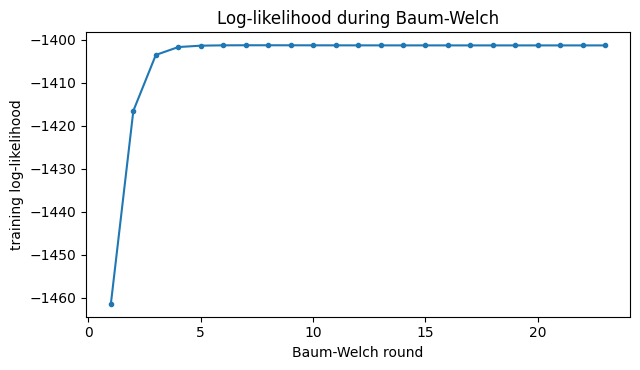

all checks passed: True


In [11]:
def fit_experiment(set_name, init="supervised", n_starts=5):
    """Train one feature set. Returns the model, the state to activity mapping, the train and test sequences and the training confusion matrix."""
    cols = z_names(FEATURE_SETS[set_name])
    train_seq, test_seq = split_sequences(cols)
    if init == "supervised":
        model = init_supervised(train_seq).fit(train_seq)
        mapping = np.arange(N_STATES)
    else:
        model = best_random_fit(train_seq, n_starts)
        truth, states = decode_sequences(model, train_seq)
        mapping = best_mapping(confusion(states, truth))
    y_tr, p_tr = decode_sequences(model, train_seq, mapping)
    return {"name": set_name, "init": init, "cols": cols, "model": model, "mapping": mapping,
            "train_seq": train_seq, "test_seq": test_seq, "train_conf": confusion(y_tr, p_tr)}


main = fit_experiment("compact (5)")
model, mapping = main["model"], main["mapping"]
history = np.array(model.history)

start_loglik = sum(start_model.log_likelihood(X) for X, _ in main["train_seq"].values())
final_loglik = sum(model.log_likelihood(X) for X, _ in main["train_seq"].values())
biggest_drop = float(max(0.0, -np.diff(history).min())) if len(history) > 1 else 0.0

train_checks = [
    check("Baum-Welch ran for more than one round", len(history) > 1),
    check("stopped because of epsilon, before the maximum rounds", model.converged),
    check("every recorded log-likelihood is finite", np.isfinite(history).all()),
    check("first recorded log-likelihood equals the starting model's", np.isclose(history[0], start_loglik)),
    check("log-likelihood went up from start to end", final_loglik > start_loglik),
    check("log-likelihood never dropped by more than 0.1 in one round", biggest_drop < 0.1),
    check("final log-likelihood matches the last recorded one", final_loglik >= history[-1] - 1e-3),
    check("start probabilities add up to 1", np.isclose(model.pi.sum(), 1)),
    check("every transition row adds up to 1", np.allclose(model.A.sum(axis=1), 1)),
    check("variances are at or above the floor", (model.variances >= VAR_FLOOR).all()),
    check("no NaN or infinity in the parameters", np.isfinite(model.means).all() and np.isfinite(model.variances).all()),
]

print("rounds:", len(history), "| converged:", model.converged, "| epsilon:", EPSILON)
print("training log-likelihood: start", round(start_loglik, 2), "-> end", round(final_loglik, 2))
print("biggest drop between two rounds:", round(biggest_drop, 6))
print("biggest change of a mean:", round(float(np.abs(model.means - start_model.means).max()), 3),
      "| biggest change of a transition probability:", round(float(np.abs(model.A - start_model.A).max()), 5))
print("train accuracy after Baum-Welch:", round(accuracy(main["train_conf"]), 4))
display(per_class_table(main["train_conf"]).round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(range(1, len(history) + 1), history, marker="o", ms=3)
ax.set_xlabel("Baum-Welch round")
ax.set_ylabel("training log-likelihood")
ax.set_title("Log-likelihood during Baum-Welch")
fig.tight_layout()
fig.savefig(FIG_DIR / "loglik_curve.png", dpi=150)
plt.show()

print("all checks passed:", all(train_checks))

### 8.1 What the training shows

Baum-Welch stopped after 23 rounds, because the log-likelihood changed by less than epsilon (0.0001). The curve climbs fast in the first 4 rounds (from -1461 to about -1402) and is almost flat after round 5, so most of the learning happens early. The total went from -1461.36 to -1401.28. The log-likelihood is meant to go up at every round, and it did, except for one very small drop of at most 0.006 in one round. I do not know exactly why. The variance floor and the pseudo count are not part of the pure algorithm and could be the reason, but a test on made up data in 8.5 showed no drop with or without them.

**The accuracy on the training recordings went down, from 0.9967 before Baum-Welch to 0.9391 after it.** Walking and jumping stay perfect. The loss is all in standing and still: 31 standing windows are decoded as still (sensitivity of standing 0.811), and 6 still windows are decoded as standing. A better likelihood does not mean better activity labels. Baum-Welch does not see the labels, it only tries to explain the data better.

In [12]:
A_after = pd.DataFrame(model.A, index=ACTIVITIES, columns=ACTIVITIES)
display(A_after.round(4))

rows = []
for name, (X, y) in main["train_seq"].items():
    path = model.decode(X)[0]
    rows.append({"recording": name, "true activity": ACTIVITIES[y[0]], "windows": len(y),
                 **{f"decoded {a}": int((path == i).sum()) for i, a in enumerate(ACTIVITIES)}})
decoded_table = pd.DataFrame(rows).set_index("recording")
display(decoded_table)

for k in (ACTIVITIES.index("standing"), ACTIVITIES.index("still")):
    print(ACTIVITIES[k], "state")
    display(pd.DataFrame({"mean before": start_model.means[k], "mean after": model.means[k],
                          "variance before": start_model.variances[k], "variance after": model.variances[k]},
                         index=main_features).round(2))

diag_checks = [
    check("transition rows add up to 1", np.allclose(A_after.sum(axis=1), 1)),
    check("every recording's decoded counts add up to its windows",
          (decoded_table[[f"decoded {a}" for a in ACTIVITIES]].sum(axis=1) == decoded_table["windows"]).all()),
    check("total decoded windows equal the training windows", decoded_table["windows"].sum() == n_windows),
]
print("all checks passed:", all(diag_checks))

,standing,walking,jumping,still
standing,0.8907,0.0036,0.0036,0.1021
walking,0.0037,0.9890,0.0036,0.0036
jumping,0.0031,0.0048,0.9890,0.0031
still,0.0817,0.0029,0.0029,0.9124


,true activity,windows,decoded standing,decoded walking,decoded jumping,decoded still
recording,,,,,,
jumping1,jumping,24,0,0,24,0
jumping3,jumping,44,0,0,44,0
jumping4,jumping,40,0,0,40,0
jumping5,jumping,56,0,0,56,0
standing1,standing,104,86,0,0,18
standing3,standing,60,47,0,0,13
still1,still,144,6,0,0,138
walking1,walking,136,0,136,0,0


standing state


,mean before,mean after,variance before,variance after
log_energy_high,-0.80,-0.79,0.05,0.05
zero_cross_rate,-0.52,-0.37,0.47,0.48
dominant_hz,-0.66,-0.59,0.14,0.21
spectral_entropy,-0.26,-0.16,0.73,0.68
corr_xz,-0.68,-0.69,0.57,0.65


still state


,mean before,mean after,variance before,variance after
log_energy_high,-1.08,-1.04,0.05,0.05
zero_cross_rate,-1.13,-1.16,0.10,0.05
dominant_hz,-0.76,-0.80,0.09,0.05
spectral_entropy,-0.16,-0.26,2.09,1.92
corr_xz,-0.20,-0.26,0.23,0.23


ok      transition rows add up to 1
ok      every recording's decoded counts add up to its windows
ok      total decoded windows equal the training windows
all checks passed: True


### 8.2 What changed during Baum-Welch

The log-likelihood went up, but the training accuracy went down, so I look at what moved. The cell shows the transition matrix after training, how each training recording is decoded, and how the means of the standing and still states changed.

### 8.3 Is it the transition matrix or the emissions?

In 8.2 the transition matrix changed a lot and the means changed a little, so there are two possible reasons for the lower accuracy. To separate them I decode the training recordings in three ways, using the trained model each time:
- trained means and variances with the trained transition matrix (the model as it is)
- trained means and variances with the old almost-identity matrix from before Baum-Welch
- the emissions alone, with no transition matrix at all, so that every window is decided by itself

The last one also shows how much the transition matrix helps in general.

In [13]:
sticky = GaussianHMM(model.pi, start_model.A, model.means, model.variances)
truth_s, pred_s = decode_sequences(sticky, main["train_seq"])
conf_sticky = confusion(truth_s, pred_s)

emission_pred = np.concatenate([model.log_emission(X).argmax(axis=1) for X, _ in main["train_seq"].values()])
conf_emission = confusion(truth_s, emission_pred)

split_checks = [
    check("same trained means in the sticky copy", np.allclose(sticky.means, model.means)),
    check("sticky matrix rows add up to 1", np.allclose(sticky.A.sum(axis=1), 1)),
    check("both versions decode every training window", conf_sticky.sum() == conf_emission.sum() == n_windows),
]

print("train accuracy, trained emissions + trained matrix :", round(accuracy(main["train_conf"]), 4))
print("train accuracy, trained emissions + sticky matrix  :", round(accuracy(conf_sticky), 4))
print("train accuracy, emissions only (no transitions)    :", round(accuracy(conf_emission), 4))
display(per_class_table(conf_emission).round(3))
print("all checks passed:", all(split_checks))

ok      same trained means in the sticky copy
ok      sticky matrix rows add up to 1
ok      both versions decode every training window
train accuracy, trained emissions + trained matrix : 0.9391
train accuracy, trained emissions + sticky matrix  : 0.9638
train accuracy, emissions only (no transitions)    : 0.8816


,windows,TP,FN,FP,TN,sensitivity,specificity
activity,,,,,,,
standing,164,109,55,16,428,0.665,0.964
walking,136,135,1,1,471,0.993,0.998
jumping,164,163,1,0,444,0.994,1.000
still,144,129,15,55,409,0.896,0.881


all checks passed: True


### 8.4 What the diagnostics show

The mistakes are only between standing and still. Jumping and walking are decoded perfectly in every training recording, and both standing recordings and the still recording have some windows decoded as the other one.

**What changed.** The means moved very little (the biggest change is 0.14), and the variances changed a bit. The transition matrix changed a lot. Standing to still went from 0.003 to 0.102, and still to standing from 0.003 to 0.082. This is not a real behaviour. No recording ever changes from one activity to another. Baum-Welch does not see the labels, so standing windows that look like still were partly counted as still, and this was counted as moves between the two states.

**Why the accuracy dropped.** The three ways of decoding in 8.3 gave these training accuracies:
- trained model as it is: 0.9391
- trained means and variances with the old almost-identity matrix: 0.9638
- emissions alone, no transition matrix: 0.8816

So the looser matrix explains about 15 windows of the loss (0.9638 to 0.9391). The starting model had 0.9967, so the other 20 or so windows come from the changed means and variances. I did not find which feature caused this. Some variances changed (for example the still state got narrower in `zero_cross_rate` and `dominant_hz`, and both now sit at the floor).

**How much the time structure helps.** If every window is decoded alone, using only the emissions, the accuracy is 0.8816 and only 66.5% of standing windows are found, because 55 of them look more like still. Viterbi with the transition matrix gives 0.94 to 0.96 on the same windows, so the HMM clearly helps. I need to be careful with this. Every training sequence has only one activity, so a matrix that says "stay" is always right here. In a real sequence where the activity changes, the same matrix would make the model slower to switch. So this gain is probably bigger than it would be in real use.

**Two weak spots in the emissions.** The still state has a variance of about 1.9 for `spectral_entropy`, which means this feature says almost nothing about still. For `log_energy_high`, the standing and still means are only about 0.25 apart and both variances are at the floor (0.05), so the floor may be limiting how well the two are separated. I did not test a smaller floor yet.

**What I take from this.** A higher likelihood did not give better labels here. I keep Baum-Welch as the main model, and in the next section I also report the starting model without Baum-Welch next to it on the unseen recordings. I decided this before looking at the test results, so I do not pick the better one afterwards.

### 8.5 Does exact Baum-Welch ever lower the log-likelihood?

In 8.1 the log-likelihood dropped by at most 0.006 in one round, and I put this down to the variance floor and the pseudo count, which are not part of the pure algorithm. This test checks it. On a small made up dataset (4 clusters, section 7), I train once with the pseudo count set to 0 and a tiny variance floor (pure Baum-Welch), and once with the settings I use everywhere else. Pure Baum-Welch must never lower the log-likelihood, apart from rounding errors. The cell puts the pseudo count back afterwards and checks that the main model did not change.

In [14]:
saved_pseudo = PSEUDO_COUNT
saved_state = (model.A.copy(), model.means.copy(), model.variances.copy(), list(model.history))

exact = init_random(toy_seq, SEED)
exact.var_floor = 1e-6
PSEUDO_COUNT = 0.0
try:
    exact.fit(toy_seq, epsilon=1e-9, max_iter=100)
finally:
    PSEUDO_COUNT = saved_pseudo

usual = init_random(toy_seq, SEED).fit(toy_seq, epsilon=1e-9, max_iter=100)

exact_diffs = np.diff(exact.history)
usual_diffs = np.diff(usual.history)

print("pure Baum-Welch   : rounds", len(exact.history), "| biggest drop", float(max(0.0, -exact_diffs.min())))
print("usual settings    : rounds", len(usual.history), "| biggest drop", float(max(0.0, -usual_diffs.min())))

mono_checks = [
    check("pure Baum-Welch ran for more than one round", len(exact.history) > 1),
    check("pure Baum-Welch log-likelihoods are finite", np.isfinite(exact.history).all()),
    check("pure Baum-Welch never lowered the log-likelihood (rounding only)", exact_diffs.min() >= -1e-6),
    check("pure Baum-Welch improved the log-likelihood overall", exact.history[-1] > exact.history[0]),
    check("usual settings log-likelihoods are finite", np.isfinite(usual.history).all()),
    check("the pseudo count is back to its usual value", PSEUDO_COUNT == saved_pseudo),
    check("the main model was not changed", np.allclose(model.A, saved_state[0]) and np.allclose(model.means, saved_state[1])
          and np.allclose(model.variances, saved_state[2]) and model.history == saved_state[3]),
]
print("all checks passed:", all(mono_checks))

pure Baum-Welch   : rounds 5 | biggest drop 0.0
usual settings    : rounds 5 | biggest drop 0.0
ok      pure Baum-Welch ran for more than one round
ok      pure Baum-Welch log-likelihoods are finite
ok      pure Baum-Welch never lowered the log-likelihood (rounding only)
ok      pure Baum-Welch improved the log-likelihood overall
ok      usual settings log-likelihoods are finite
ok      the pseudo count is back to its usual value
ok      the main model was not changed
all checks passed: True


**What the test shows.**

On the made up data, pure Baum-Welch (pseudo count 0, tiny variance floor) never lowered the log-likelihood. The biggest drop was 0.0 over its 5 rounds, which is what exact EM should do. So the E step and the M step agree with the theory, at least on this example. The run with my usual settings also had no drop on this data.

So this test does not explain the drop of 0.006 that I saw on the real training data in 8.1. The toy data is easy and stops after 5 rounds, so only 4 changes were checked. I still think that the variance floor and the pseudo count are the likely reason, because they are not part of the pure algorithm, but I did not show this on the real data. The drop is tiny compared with the total log-likelihood (about -1401), and the model stopped normally, so I do not think it changes any result.

# 9. Test on the unseen recordings

The four test recordings (jumping2, standing2, still2 and walking2) were not used for the normalisation, the training or any choice I made so far. Each one is decoded with Viterbi, and the decoded activity of every window is compared with the true activity.

I report two models on the same windows: the trained model (main), and the starting model without Baum-Welch, as a comparison. I chose these two before looking at any test result.

What to keep in mind when reading the results:
- Each test recording has only one activity, so a model that says "stay" is always right on the transitions. Only the emissions can make a mistake here.
- The test set has 164 still windows and only 36 jumping windows, so the overall accuracy is pulled towards still. Sensitivity and specificity for each activity are the fairer numbers.
- The test recordings were held at a different angle for standing, walking and jumping (section 19 of the data notebook). The main model does not use the orientation features, which should help.

ok      the four expected test recordings are used
ok      no test recording was used for training
ok      360 test windows in total
ok      test windows have the same features as the training windows
ok      confusion matrices count every test window
ok      windows per activity match the data
ok      TP + FN equals the windows of each activity
ok      sensitivity and specificity are between 0 and 1
ok      test log-likelihood is finite for every recording
test windows: 360
overall test accuracy, trained model (main): 0.9417
overall test accuracy, start model (no Baum-Welch): 1.0

Trained model (main)


,windows,TP,FN,FP,TN,sensitivity,specificity
activity,,,,,,,
standing,80,61,19,2,278,0.762,0.993
walking,80,80,0,0,280,1.000,1.000
jumping,36,36,0,0,324,1.000,1.000
still,164,162,2,19,177,0.988,0.903


Start model, no Baum-Welch (comparison)


,windows,TP,FN,FP,TN,sensitivity,specificity
activity,,,,,,,
standing,80,80,0,0,280,1.0,1.0
walking,80,80,0,0,280,1.0,1.0
jumping,36,36,0,0,324,1.0,1.0
still,164,164,0,0,196,1.0,1.0


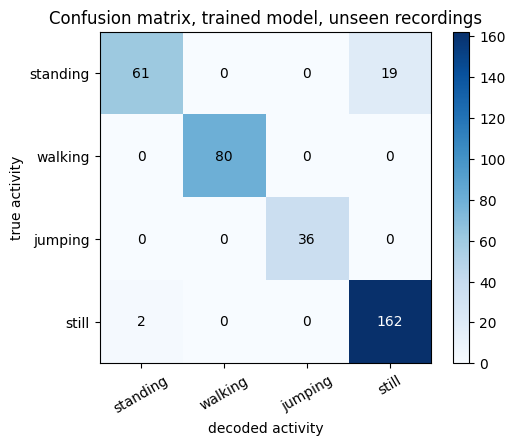

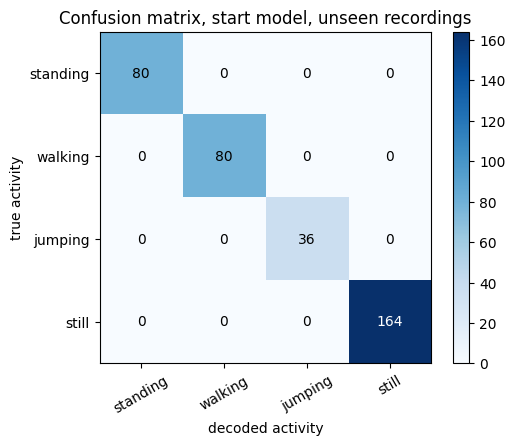

windows  as standing  as walking  as jumping  as still  \
recording model                                                             
jumping2  trained       36            0           0          36         0   
          start         36            0           0          36         0   
standing2 trained       80           61           0           0        19   
          start         80           80           0           0         0   
still2    trained      164            2           0           0       162   
          start        164            0           0           0       164   
walking2  trained       80            0          80           0         0   
          start         80            0          80           0         0   

                   accuracy  
recording model              
jumping2  trained     1.000  
          start       1.000  
standing2 trained     0.762  
          start       1.000  
still2    trained     0.988  
          start       1.000  
walking2  trained     1.000  
          start       1.000

ok      per recording counts add up to the windows
all checks passed: True


In [15]:
def plot_confusion(m, title, name):
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(m, cmap="Blues")
    ax.set_xticks(range(N_STATES)); ax.set_xticklabels(ACTIVITIES, rotation=30)
    ax.set_yticks(range(N_STATES)); ax.set_yticklabels(ACTIVITIES)
    for i in range(N_STATES):
        for j in range(N_STATES):
            ax.text(j, i, int(m[i, j]), ha="center", va="center",
                    color="white" if m[i, j] > m.max() / 2 else "black")
    ax.set_xlabel("decoded activity")
    ax.set_ylabel("true activity")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150)
    plt.show()


def evaluate(m, sequences, mp=None):
    """Decode the sequences. Returns the confusion matrix and the per activity table."""
    truth, pred = decode_sequences(m, sequences, mp)
    conf = confusion(truth, pred)
    return conf, per_class_table(conf)


test_seq = main["test_seq"]
n_test = sum(len(s[1]) for s in test_seq.values())
conf_main, table_main = evaluate(model, test_seq, mapping)
conf_start, table_start = evaluate(start_model, test_seq)
expected_counts = data[data["split"] == "test"]["activity"].value_counts().reindex(ACTIVITIES)

test_checks = [
    check("the four expected test recordings are used", set(test_seq) == {"jumping2", "standing2", "still2", "walking2"}),
    check("no test recording was used for training", not (set(test_seq) & set(main["train_seq"]))),
    check("360 test windows in total", n_test == 360),
    check("test windows have the same features as the training windows", next(iter(test_seq.values()))[0].shape[1] == len(main["cols"])),
    check("confusion matrices count every test window", conf_main.sum() == n_test == conf_start.sum()),
    check("windows per activity match the data", (table_main["windows"].values == expected_counts.values).all()),
    check("TP + FN equals the windows of each activity", ((table_main["TP"] + table_main["FN"]) == table_main["windows"]).all()),
    check("sensitivity and specificity are between 0 and 1", table_main[["sensitivity", "specificity"]].stack().between(0, 1).all()),
    check("test log-likelihood is finite for every recording", all(np.isfinite(model.log_likelihood(X)) for X, _ in test_seq.values())),
]

print("test windows:", n_test)
print("overall test accuracy, trained model (main):", round(accuracy(conf_main), 4))
print("overall test accuracy, start model (no Baum-Welch):", round(accuracy(conf_start), 4))

print("\nTrained model (main)")
display(table_main.round(3))
print("Start model, no Baum-Welch (comparison)")
display(table_start.round(3))

plot_confusion(conf_main, "Confusion matrix, trained model, unseen recordings", "confusion_test.png")
plot_confusion(conf_start, "Confusion matrix, start model, unseen recordings", "confusion_test_start.png")

rows = []
for name, (X, y) in test_seq.items():
    for label, m, mp in [("trained", model, mapping), ("start", start_model, None)]:
        path = m.decode(X)[0]
        path = path if mp is None else mp[path]
        rows.append({"recording": name, "model": label, "windows": len(y),
                     **{f"as {a}": int((path == i).sum()) for i, a in enumerate(ACTIVITIES)},
                     "accuracy": round(float((path == y).mean()), 3)})
per_recording = pd.DataFrame(rows).set_index(["recording", "model"])
display(per_recording)

test_checks.append(check("per recording counts add up to the windows",
                         (per_recording[[f"as {a}" for a in ACTIVITIES]].sum(axis=1) == per_recording["windows"]).all()))
print("all checks passed:", all(test_checks))

### 9.1 What the test results show

**Main model (trained with Baum-Welch).** The overall accuracy on the unseen recordings is 0.9417 (339 of 360 windows). Walking and jumping are perfect (sensitivity and specificity 1.000). Standing has a sensitivity of 0.762: 19 of its 80 windows are decoded as still, and all of them are in the standing2 recording. Still has a sensitivity of 0.988 (2 of 164 windows decoded as standing), but a specificity of only 0.903, because those 19 standing windows count as false alarms for still. So all the mistakes are between standing and still, as the training results and the PCA picture suggested.

**Starting model (comparison, no Baum-Welch).** It decodes all 360 windows correctly (accuracy 1.0, every sensitivity and specificity 1.000). So Baum-Welch made the unseen result worse, and not better. This is the same direction as on the training recordings (section 8), where the accuracy went from 0.9967 to 0.9391. I decided before looking at the test results that the Baum-Welch model is the main one, so I report both and I do not switch to the better looking one.

**I do not trust the 1.0 too much.** Each test recording has only one activity, and the starting model almost never switches state (0.99 for staying). So Viterbi mostly picks one state for the whole recording by looking at all of its windows together. The result says that the windows of each recording look like the right activity on average. It does not say that the model can classify every single window correctly. The glued sequence in section 11 and the comparison without transitions are better tests of this.

**How much this can say.** There are only four test recordings, from one person and one phone, and the windows overlap by half, so the 80 windows of standing2 are worth about 40 independent windows. The 19 mistakes are all from one recording. So I only say that the model works on this data, and I do not claim anything about other people or other phones.

**I do not yet know why standing2 is the harder one.** It was held at a different angle than the training standing recordings, but the main model does not use the orientation features, so the angle is not an obvious reason. The decoded sequence plot in section 11 will show if the 19 windows are one block or are spread out.

# 10. Transition matrix and emissions

**Transition matrix.** Row i, column j is the probability of going from state i to state j between two neighbouring windows. The left picture is the matrix before Baum-Welch and the right one is the trained matrix. Since no recording ever changes its activity, anything other than "stay" in these matrices is not a measured behaviour. In the starting matrix it only comes from the pseudo count, and in the trained one it comes from Baum-Welch moving some standing and still windows between the two states.

**Emissions.** Every state has one Gaussian for each of the 5 features (on the normalised scale). The curves show how much the states overlap. Where two curves sit on top of each other, that feature can not tell the two activities apart. Walking and jumping are far from the rest, so the interesting pair is standing and still. For this pair I also calculate a separation number for every feature (the Bhattacharyya distance between the two Gaussians). A bigger number means the two Gaussians are easier to tell apart, and 0 means they are the same.

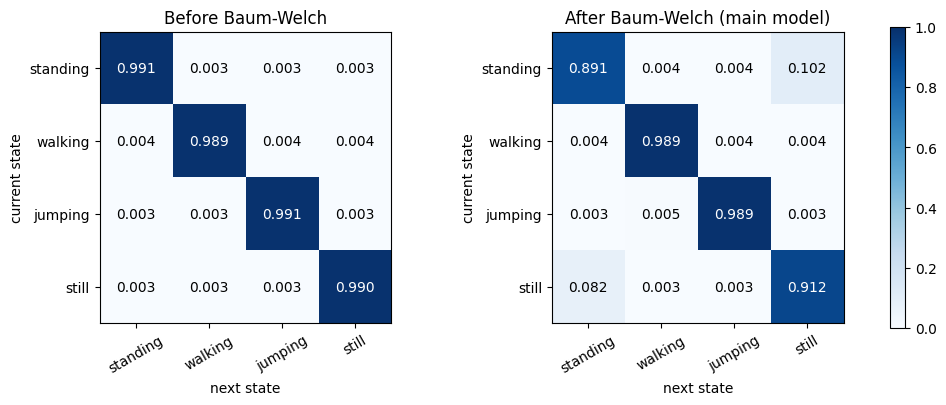

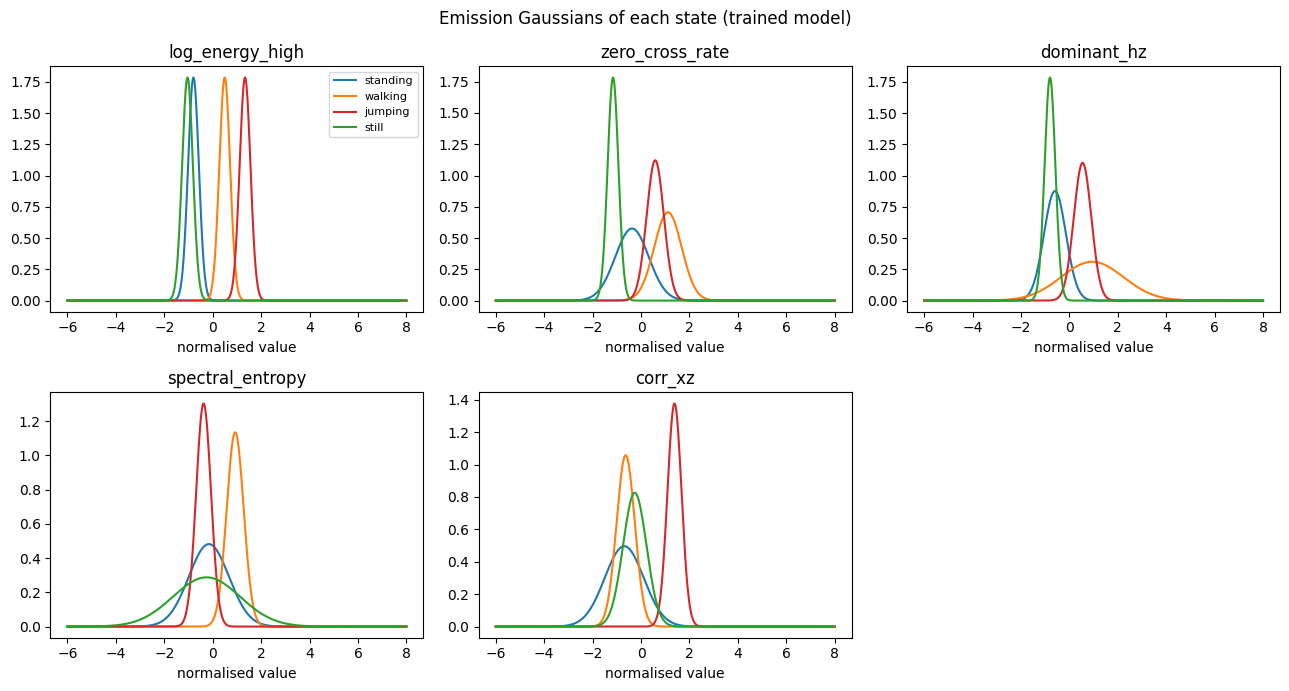

,log_energy_high,zero_cross_rate,dominant_hz,spectral_entropy,corr_xz
mean,,,,,
standing,-0.79,-0.37,-0.59,-0.16,-0.69
walking,0.50,1.11,0.94,0.93,-0.63
jumping,1.34,0.59,0.55,-0.38,1.38
still,-1.04,-1.16,-0.80,-0.26,-0.26


,log_energy_high,zero_cross_rate,dominant_hz,spectral_entropy,corr_xz
standard deviation,,,,,
standing,0.22,0.69,0.46,0.83,0.80
walking,0.22,0.57,1.29,0.35,0.38
jumping,0.22,0.36,0.36,0.31,0.29
still,0.22,0.22,0.22,1.39,0.48


,standing vs still separation
log_energy_high,0.152
zero_cross_rate,0.558
dominant_hz,0.158
spectral_entropy,0.065
corr_xz,0.116


ok      trained matrix in activity order rows add up to 1
ok      starting matrix rows add up to 1
ok      the plotted matrix is the model's matrix
ok      every emission curve adds up to about 1
ok      emission shapes are (states, features)
ok      separation numbers are not negative
ok      the three figures were saved
all checks passed: True


In [16]:
def in_activity_order(m, mp):
    order = np.argsort(mp)
    return m.A[np.ix_(order, order)], m.means[order], m.variances[order], m.pi[order]


def draw_matrix(ax, A, title):
    im = ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(N_STATES)); ax.set_xticklabels(ACTIVITIES, rotation=30)
    ax.set_yticks(range(N_STATES)); ax.set_yticklabels(ACTIVITIES)
    for i in range(N_STATES):
        for j in range(N_STATES):
            ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center",
                    color="white" if A[i, j] > 0.5 else "black")
    ax.set_xlabel("next state")
    ax.set_ylabel("current state")
    ax.set_title(title)
    return im


A_start, _, _, _ = in_activity_order(start_model, np.arange(N_STATES))
A_main, means_main, vars_main, pi_main = in_activity_order(model, mapping)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"wspace": 0.55})
draw_matrix(axes[0], A_start, "Before Baum-Welch")
im = draw_matrix(axes[1], A_main, "After Baum-Welch (main model)")
fig.colorbar(im, ax=axes, shrink=0.85)
fig.savefig(FIG_DIR / "transition_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

grid = np.linspace(-6, 8, 701)
dx = grid[1] - grid[0]
n_feat = len(main["cols"])
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.ravel()
pdfs = np.empty((N_STATES, n_feat, len(grid)))
for j, col in enumerate(main["cols"]):
    for k, activity in enumerate(ACTIVITIES):
        m, v = means_main[k, j], vars_main[k, j]
        pdfs[k, j] = np.exp(-0.5 * (grid - m) ** 2 / v) / np.sqrt(2 * np.pi * v)
        axes[j].plot(grid, pdfs[k, j], color=PALETTE[k], label=activity)
    axes[j].set_title(col[2:])
    axes[j].set_xlabel("normalised value")
axes[0].legend(fontsize=8)
for ax in axes[n_feat:]:
    ax.axis("off")
fig.suptitle("Emission Gaussians of each state (trained model)")
fig.tight_layout()
fig.savefig(FIG_DIR / "emissions.png", dpi=150)
plt.show()

names = [c[2:] for c in main["cols"]]
display(pd.DataFrame(means_main, index=ACTIVITIES, columns=names).round(2).rename_axis("mean"))
display(pd.DataFrame(np.sqrt(vars_main), index=ACTIVITIES, columns=names).round(2).rename_axis("standard deviation"))

s, t = ACTIVITIES.index("standing"), ACTIVITIES.index("still")
vs, vt = vars_main[s], vars_main[t]
separation_st = 0.25 * (means_main[s] - means_main[t]) ** 2 / (vs + vt) + 0.5 * np.log((vs + vt) / (2 * np.sqrt(vs * vt)))
display(pd.Series(separation_st, index=names, name="standing vs still separation").round(3).to_frame())

plot_checks = [
    check("trained matrix in activity order rows add up to 1", np.allclose(A_main.sum(axis=1), 1)),
    check("starting matrix rows add up to 1", np.allclose(A_start.sum(axis=1), 1)),
    check("the plotted matrix is the model's matrix", np.allclose(A_main, model.A[np.ix_(np.argsort(mapping), np.argsort(mapping))])),
    check("every emission curve adds up to about 1", np.allclose(pdfs.sum(axis=2) * dx, 1, atol=0.02)),
    check("emission shapes are (states, features)", means_main.shape == vars_main.shape == (N_STATES, n_feat)),
    check("separation numbers are not negative", (separation_st >= -1e-9).all()),
    check("the three figures were saved", all((FIG_DIR / f).exists() for f in ["transition_heatmap.png", "emissions.png"])),
]
print("all checks passed:", all(plot_checks))

### 10.1 What the transition matrix and the emissions show

**Transition matrix.** Before Baum-Welch every state stays with a probability of 0.989 to 0.991 and every move has a probability of 0.003 to 0.004. After Baum-Welch walking and jumping are almost the same (0.989). Standing and still changed: standing stays with 0.891 and goes to still with 0.102, and still stays with 0.912 and goes to standing with 0.082. This is the only real change in the matrix, and it is not a real behaviour, because no recording ever changes its activity. Baum-Welch moved some standing and still windows between the two states, and this made the two states look like they switch often. The stay probabilities for standing and still (0.89 and 0.91) mean the model expects those states to last about 9 to 11 windows, while the real recordings last 60 to 164 windows. This is why the trained model switches more easily and makes the standing to still mistakes found in sections 8 and 9. Walking and jumping are kept apart from everything else, with almost no probability of moving to or from any other state.

**Emissions.** The picture is clear for walking and jumping and unclear for standing and still.
- `corr_xz` separates jumping (mean 1.38) from the others (-0.7 to -0.3). `log_energy_high` and `zero_cross_rate` put walking and jumping on the high side and standing and still on the low side.
- Standing and still overlap in most features. The standing and still curves sit on top of each other in `log_energy_high`, `dominant_hz` and `corr_xz`.
- The best feature to tell standing from still is `zero_cross_rate`: still has a narrow curve at -1.16 and standing is wider and centred at -0.37. The separation number is 0.558, much higher than the next ones (`dominant_hz` 0.158, `log_energy_high` 0.152, `corr_xz` 0.116). `spectral_entropy` is the weakest (0.065). It is not a surprise: the still state has a standard deviation of 1.39 for this feature, which is so wide that it says almost nothing.
- **The variance floor is binding.** In `log_energy_high` all four states have the same standard deviation of 0.22, which is the floor (the variance floor 0.05 gives 0.22). The same happens for the still state in `zero_cross_rate` and `dominant_hz`. So for these features the curves show my floor and not the real spread of the data. In the boxplots standing and still looked well separated in `log_energy_high` (around -3.1 and -4.0 in the raw values), but the floor makes the two curves wide enough to overlap. I think a smaller floor would separate them better, but it can also make the model too sure of itself for still windows that sit exactly at the floor of the log scale. I have not tested this yet, so I treat it as an idea for section 12 and not as a result.
- The standing state has wide curves in `zero_cross_rate`, `spectral_entropy` and `corr_xz` (standard deviation 0.7 to 0.8). A wide state can take windows that belong to other states. This fits with standing being the activity that loses windows to still.

# 11. Decoded sequences

The test recordings are decoded in two ways.

**A glued sequence (made up).** I glued the four test recordings together in the random order chosen in section 3. The true activity changes 3 times, at the dotted lines. This is not a real recording of a person changing activity. It is a way to see if Viterbi can follow a switch when the evidence changes, which the single recordings can not show. The table also gives, for each recording in the glued sequence, how many windows pass before the decoded activity becomes correct.

**Each test recording alone.** Decoded on its own, which is the real situation. This comes next.

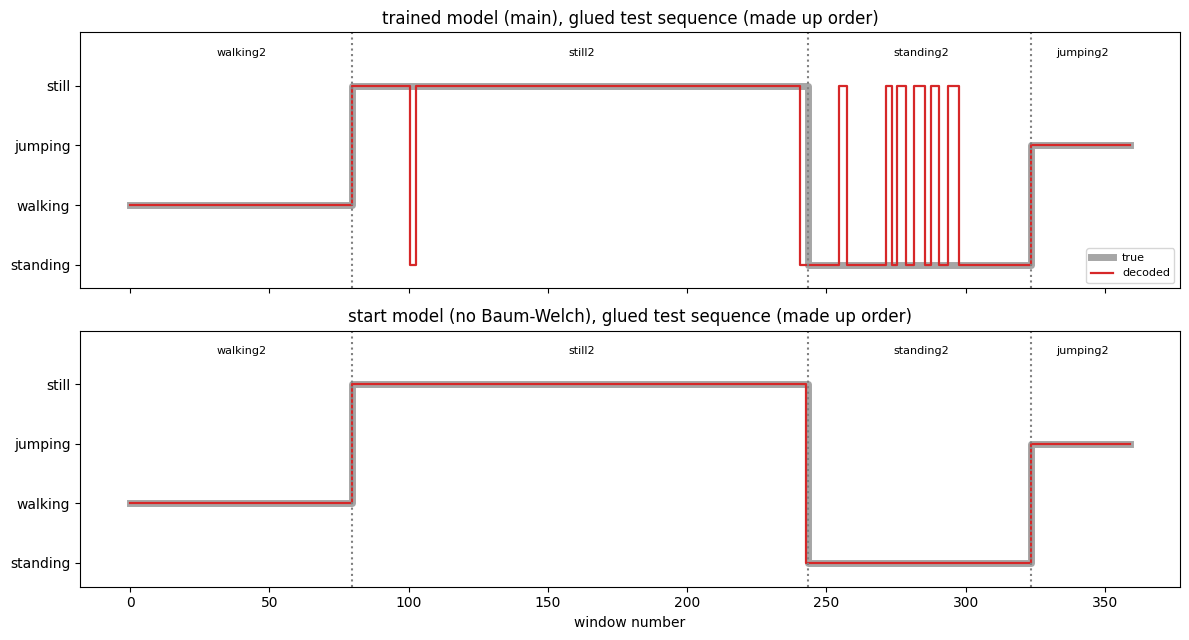

windows  correct  \
model                       recording                     
trained model (main)        walking2        80       80   
                            still2         164      159   
                            standing2       80       61   
                            jumping2        36       36   
start model (no Baum-Welch) walking2        80       80   
                            still2         164      163   
                            standing2       80       80   
                            jumping2        36       36   

                                       windows before first correct  
model                       recording                                
trained model (main)        walking2                              0  
                            still2                                0  
                            standing2                             0  
                            jumping2                              0  
start model (no Baum-Welch) walking2                              0  
                            still2                                0  
                            standing2                             0  
                            jumping2                              0

trained model (main): accuracy 0.9333 | decoded switches 17 (true switches 3)
start model (no Baum-Welch): accuracy 0.9972 | decoded switches 3 (true switches 3)
ok      all four test recordings are in the glued order
ok      glued sequence has all 360 windows
ok      the true activity changes exactly 3 times
ok      every recording is one activity
ok      decoded labels are valid activities
ok      segment counts add up to 360 for each model
ok      segment correct counts match the overall accuracy
all checks passed: True


In [17]:
glued_X = np.vstack([test_seq[n][0] for n in STITCH_ORDER])
glued_y = np.concatenate([test_seq[n][1] for n in STITCH_ORDER])
seg_len = np.array([len(test_seq[n][1]) for n in STITCH_ORDER])
seg_end = np.cumsum(seg_len)
seg_start = seg_end - seg_len

glued_pred = {
    "trained model (main)": mapping[model.decode(glued_X)[0]],
    "start model (no Baum-Welch)": start_model.decode(glued_X)[0],
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
t = np.arange(len(glued_y))
for ax, (label, pred) in zip(axes, glued_pred.items()):
    ax.step(t, glued_y, where="mid", lw=5, alpha=0.35, color="black", label="true")
    ax.step(t, pred, where="mid", lw=1.6, color="tab:red", label="decoded")
    for b in seg_start[1:]:
        ax.axvline(b - 0.5, color="grey", ls=":")
    for name, s0, s1 in zip(STITCH_ORDER, seg_start, seg_end):
        ax.text((s0 + s1) / 2, 3.5, name, ha="center", fontsize=8)
    ax.set_yticks(range(N_STATES))
    ax.set_yticklabels(ACTIVITIES)
    ax.set_ylim(-0.4, 3.9)
    ax.set_title(f"{label}, glued test sequence (made up order)")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].set_xlabel("window number")
fig.tight_layout()
fig.savefig(FIG_DIR / "decoded_glued.png", dpi=150)
plt.show()

rows = []
for label, pred in glued_pred.items():
    for name, s0, s1 in zip(STITCH_ORDER, seg_start, seg_end):
        right = np.where(pred[s0:s1] == glued_y[s0:s1])[0]
        rows.append({"model": label, "recording": name, "windows": int(s1 - s0),
                     "correct": int((pred[s0:s1] == glued_y[s0:s1]).sum()),
                     "windows before first correct": int(right[0]) if len(right) else None})
glued_table = pd.DataFrame(rows).set_index(["model", "recording"])
display(glued_table)

true_switches = int((np.diff(glued_y) != 0).sum())
for label, pred in glued_pred.items():
    print(f"{label}: accuracy {float((pred == glued_y).mean()):.4f} | decoded switches {int((np.diff(pred) != 0).sum())} (true switches {true_switches})")

glued_checks = [
    check("all four test recordings are in the glued order", sorted(STITCH_ORDER) == sorted(test_seq)),
    check("glued sequence has all 360 windows", len(glued_y) == 360 == seg_end[-1]),
    check("the true activity changes exactly 3 times", true_switches == 3),
    check("every recording is one activity", all(len(set(test_seq[n][1])) == 1 for n in STITCH_ORDER)),
    check("decoded labels are valid activities", all(set(np.unique(p)) <= set(range(N_STATES)) for p in glued_pred.values())),
    check("segment counts add up to 360 for each model", all(glued_table.loc[l, "windows"].sum() == 360 for l in glued_pred)),
    check("segment correct counts match the overall accuracy", all(
        glued_table.loc[l, "correct"].sum() == int((glued_pred[l] == glued_y).sum()) for l in glued_pred)),
]
print("all checks passed:", all(glued_checks))

### 11.1 What the glued sequence shows

**Both models follow the real switches.** In both pictures the decoded line changes at the three dotted lines, with no delay (the first window of every recording is decoded correctly). So Viterbi can follow a change of activity when the features change. This also shows that the 1.0 of the start model in section 9 was not only a vote over each whole recording.

**Start model (no Baum-Welch).** It decodes 359 of 360 windows correctly (0.9972) and makes exactly 3 switches, the same as the real sequence. Its one wrong window is next to the boundary between still2 and standing2, where it switches one window too early.

**Trained model (main).** It decodes 336 of 360 windows correctly (0.9333) and makes 17 switches, while the real sequence has 3. The 14 extra switches are 7 short excursions: one inside still2 and six inside standing2. In standing2 the wrong windows are not one block. The decoded line jumps to still for a few windows, comes back to standing, and does this again and again. This is what the looser standing and still transitions (about 0.1) in the trained matrix allow. When a few standing windows look like still, the model follows them and does not stay in standing.

**Is this realistic?** The start model's 3 switches look like the real activity. The trained model's 17 switches in 360 windows are not realistic. It would mean a person changes between standing and still about every 20 seconds and goes back after 2 or 3 seconds. Nobody does this, so I see the flickering as a weakness of the trained model and not as a real behaviour.

**How much this can say.** The glued sequence is made up. Its switches are sudden (one recording ends and another one begins), and a real change of activity is slower, with windows in between that look like both. So following these switches is easier than following real ones. Also, the glued and the single recording results are not exactly the same (still2 has 5 wrong windows here and 2 in section 9 for the trained model), because Viterbi looks at the whole sequence. The differences are small.

### 11.2 Each test recording decoded alone

This is the real situation: one recording, one activity. The plot shows the true activity, the trained model and the start model for every test recording. The table counts how many windows are wrong, how many separate runs of wrong windows there are, and how long the longest run is. A model that flickers has many short runs, and a model with one block of errors has one long run.

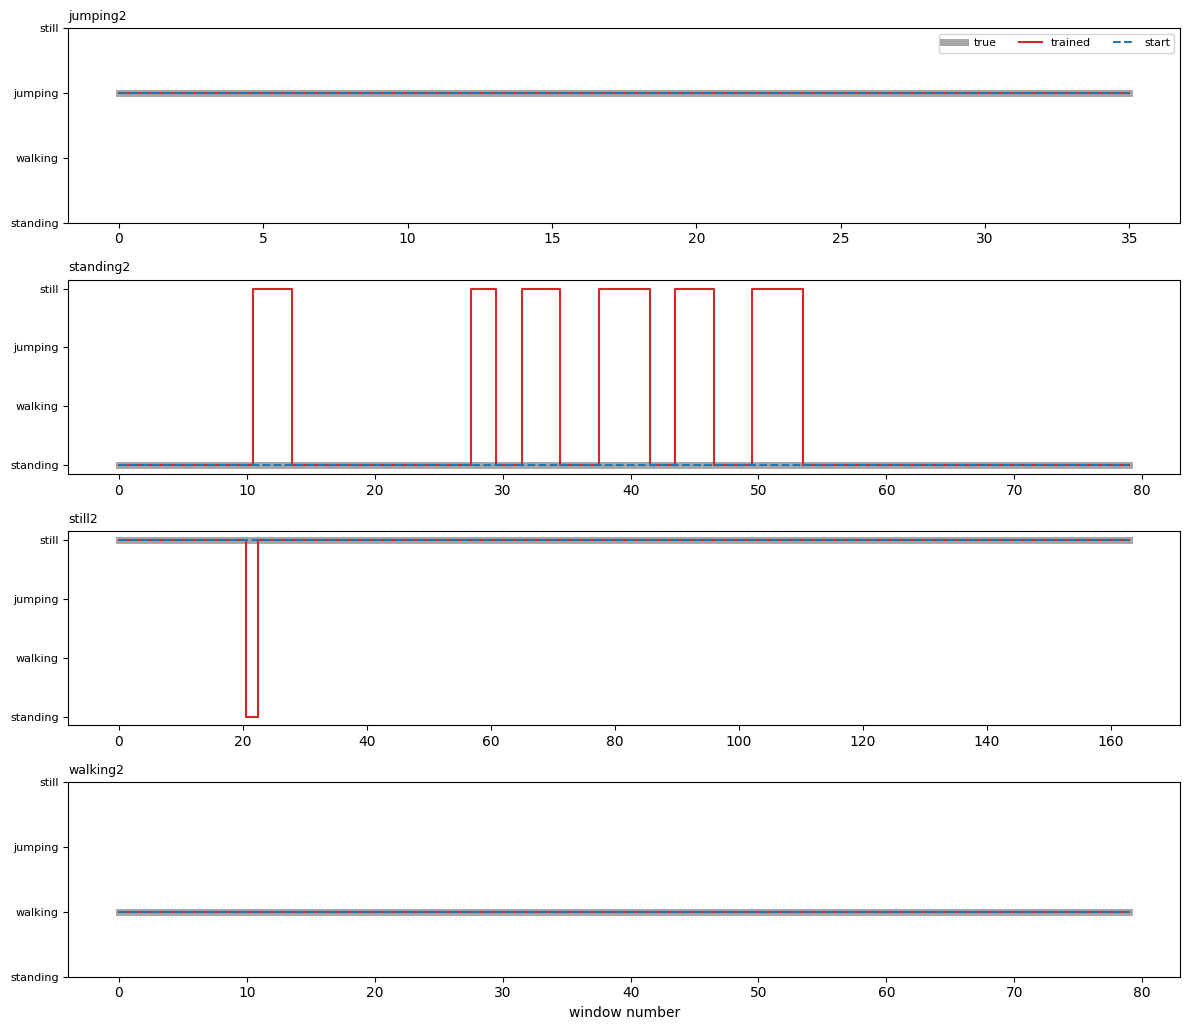

windows  correct  wrong runs  longest wrong run  \
recording model                                                      
jumping2  trained       36       36           0                  0   
          start         36       36           0                  0   
standing2 trained       80       61           6                  4   
          start         80       80           0                  0   
still2    trained      164      162           1                  2   
          start        164      164           0                  0   
walking2  trained       80       80           0                  0   
          start         80       80           0                  0   

                   decoded switches  wrong windows  
recording model                                     
jumping2  trained                 0              0  
          start                   0              0  
standing2 trained                12             19  
          start                   0              0  
still2    trained                 2              2  
          start                   0              0  
walking2  trained                 0              0  
          start                   0              0

ok      correct + wrong windows equal the windows
ok      the wrong runs add up to the wrong windows
ok      accuracies match the table in section 9
ok      every test recording appears for both models
all checks passed: True


In [18]:
def wrong_runs(wrong):
    lengths, run = [], 0
    for w in wrong:
        if w:
            run += 1
        elif run:
            lengths.append(run)
            run = 0
    if run:
        lengths.append(run)
    return lengths


alone_rows = []
fig, axes = plt.subplots(len(test_seq), 1, figsize=(12, 2.6 * len(test_seq)))
for ax, (name, (X, y)) in zip(axes, test_seq.items()):
    t = np.arange(len(y))
    ax.step(t, y, where="mid", lw=5, alpha=0.35, color="black", label="true")
    for label, m, mp, color, style in [("trained", model, mapping, "tab:red", "-"),
                                       ("start", start_model, None, "tab:blue", "--")]:
        path = m.decode(X)[0]
        path = path if mp is None else mp[path]
        ax.step(t, path, where="mid", lw=1.5, color=color, ls=style, label=label)
        runs = wrong_runs(path != y)
        alone_rows.append({"recording": name, "model": label, "windows": len(y),
                           "correct": int((path == y).sum()), "wrong runs": len(runs),
                           "longest wrong run": max(runs) if runs else 0,
                           "decoded switches": int((np.diff(path) != 0).sum()),
                           "wrong windows": int((path != y).sum()), "_run_total": int(sum(runs))})
    ax.set_yticks(range(N_STATES))
    ax.set_yticklabels(ACTIVITIES, fontsize=8)
    ax.set_title(name, loc="left", fontsize=9)
axes[0].legend(loc="upper right", fontsize=8, ncol=3)
axes[-1].set_xlabel("window number")
fig.tight_layout()
fig.savefig(FIG_DIR / "decoded_each_test_recording.png", dpi=150)
plt.show()

alone_table = pd.DataFrame(alone_rows).set_index(["recording", "model"])
display(alone_table.drop(columns="_run_total"))

alone_checks = [
    check("correct + wrong windows equal the windows", ((alone_table["correct"] + alone_table["wrong windows"]) == alone_table["windows"]).all()),
    check("the wrong runs add up to the wrong windows", (alone_table["_run_total"] == alone_table["wrong windows"]).all()),
    check("accuracies match the table in section 9", all(
        np.isclose(round(alone_table.loc[idx, "correct"] / alone_table.loc[idx, "windows"], 3), per_recording.loc[idx, "accuracy"])
        for idx in alone_table.index)),
    check("every test recording appears for both models", len(alone_table) == 2 * len(test_seq)),
]
print("all checks passed:", all(alone_checks))

**What the plots and the table show.**

Decoded alone, jumping2 and walking2 are perfect for both models. The start model also decodes standing2 (80 of 80) and still2 (164 of 164) without any mistake.

The trained model has the flickering that I saw in the glued sequence. In standing2 it gets 61 of 80 windows right. The 19 wrong windows are 6 separate runs of 2 to 4 windows (the longest is 4), spread between about window 10 and window 54. The windows in the last part of the recording are all correct. I did not check what is different in the recording there. In still2 it has one short dip of 2 windows, near window 21. So the 12 switches in standing2 and the 2 in still2 are all mistakes, because a single recording never changes activity. This confirms that the flickering is not an effect of gluing the recordings together.

### 11.3 Transitions or emissions? The same windows without a transition matrix

In section 9 the start model got every window right, but Viterbi uses the transition matrix, which almost never switches state. To see what the emissions do by themselves, I decode every test window on its own, with the state that has the highest emission probability and no transition matrix. The table compares this with Viterbi for both models. Before this, the cell checks the Viterbi code in one more way: a model with a flat transition matrix (every move equally likely) must give the same answer as picking the best emission for each window.

In [19]:
def emission_only(m, mp, sequences):
    """Decode every window alone with its best emission, with no transition matrix."""
    truth, pred = [], []
    for X, y in sequences.values():
        best = m.log_emission(X).argmax(axis=1)
        truth.append(y)
        pred.append(best if mp is None else mp[best])
    return np.concatenate(truth), np.concatenate(pred)


first_X = next(iter(test_seq.values()))[0]
flat = GaussianHMM(np.full(N_STATES, 1 / N_STATES), np.full((N_STATES, N_STATES), 1 / N_STATES),
                   model.means, model.variances)

summary_rows = []
for label, m, mp, conf_v in [("trained model (main)", model, mapping, conf_main),
                             ("start model (no Baum-Welch)", start_model, None, conf_start)]:
    truth_e, pred_e = emission_only(m, mp, test_seq)
    conf_e = confusion(truth_e, pred_e)
    for how, conf in [("Viterbi (with transitions)", conf_v), ("emissions only", conf_e)]:
        table = per_class_table(conf)
        summary_rows.append({"model": label, "decoding": how, "accuracy": accuracy(conf),
                             **{f"sensitivity {a}": table.loc[a, "sensitivity"] for a in ACTIVITIES},
                             "specificity still": table.loc["still", "specificity"],
                             "_total": int(conf.sum())})
summary = pd.DataFrame(summary_rows).set_index(["model", "decoding"])
display(summary.drop(columns="_total").round(3))

emission_checks = [
    check("every table row counts all 360 test windows", (summary["_total"] == 360).all()),
    check("Viterbi with a flat transition matrix equals best emission per window",
          np.array_equal(flat.decode(first_X)[0], flat.log_emission(first_X).argmax(axis=1))),
    check("emissions only and Viterbi results are valid accuracies", summary["accuracy"].between(0, 1).all()),
]
print("all checks passed:", all(emission_checks))

accuracy  \
model                       decoding                               
trained model (main)        Viterbi (with transitions)     0.942   
                            emissions only                 0.892   
start model (no Baum-Welch) Viterbi (with transitions)     1.000   
                            emissions only                 0.883   

                                                        sensitivity standing  \
model                       decoding                                           
trained model (main)        Viterbi (with transitions)                 0.762   
                            emissions only                             0.638   
start model (no Baum-Welch) Viterbi (with transitions)                 1.000   
                            emissions only                             0.700   

                                                        sensitivity walking  \
model                       decoding                                          
trained model (main)        Viterbi (with transitions)                  1.0   
                            emissions only                              1.0   
start model (no Baum-Welch) Viterbi (with transitions)                  1.0   
                            emissions only                              1.0   

                                                        sensitivity jumping  \
model                       decoding                                          
trained model (main)        Viterbi (with transitions)                  1.0   
                            emissions only                              1.0   
start model (no Baum-Welch) Viterbi (with transitions)                  1.0   
                            emissions only                              1.0   

                                                        sensitivity still  \
model                       decoding                                        
trained model (main)        Viterbi (with transitions)              0.988   
                            emissions only                          0.939   
start model (no Baum-Welch) Viterbi (with transitions)              1.000   
                            emissions only                          0.890   

                                                        specificity still  
model                       decoding                                       
trained model (main)        Viterbi (with transitions)              0.903  
                            emissions only                          0.852  
start model (no Baum-Welch) Viterbi (with transitions)              1.000  
                            emissions only                          0.878

ok      every table row counts all 360 test windows
ok      Viterbi with a flat transition matrix equals best emission per window
ok      emissions only and Viterbi results are valid accuracies
all checks passed: True


**What the emissions-only table shows.**

Without any transition matrix, every window is decided alone from its 5 features. The accuracy is 0.892 for the trained model and 0.883 for the start model. This is the fairest number for how well the features and the Gaussians can recognise a window by themselves.
- Walking and jumping are still perfect (sensitivity 1.0).
- Standing is the weak one: its sensitivity is 0.638 for the trained model and 0.700 for the start model. About 25 to 29 of the 80 standing2 windows look more like still when they are judged alone.
- Still is found with 0.939 (trained) and 0.890 (start), and its specificity is 0.852 and 0.878.

**What the transition matrix adds.** For the start model the accuracy goes from 0.883 to 1.000 when Viterbi is used, so all of its mistakes are fixed by the almost-never-switching matrix. For the trained model it goes from 0.892 to 0.942, so the looser matrix fixes only some of them (standing goes from 0.638 to 0.762). This is the main reason that the start model looks perfect in section 9: not that every window is easy, but that the matrix forces each whole recording into one state. Since every test recording has one activity, this is always the right thing to do, so the 1.000 is partly a result of how the test data is built. I report both: 0.88 to 0.89 is the accuracy for single windows, and 0.94 and 1.00 are the accuracies with the time structure on recordings that never change.

**Baum-Welch and the emissions.** On the test windows, the trained emissions are about as good as the starting ones (0.892 and 0.883). So on this data, the loss from Baum-Welch in section 9 seems to come from the looser transition matrix and not from worse emissions. I did not decode the test windows with the trained emissions and the old matrix, so this is a reading and not a tested result.

# 12. Other feature sets, a random start and the variance floor

### 12.1 Does the choice of features matter?

The main model uses 5 features. Here I repeat the training with four sets: all 14 features, the 11 motion features (no orientation), the compact 5 (main), and the compact 5 plus the 3 orientation features. For each set I train with Baum-Welch from the supervised start, and I also keep the start model without Baum-Welch. Each is decoded on the unseen recordings with Viterbi and with the emissions only.

The main model was chosen before this table, from the training tables, and it stays the main model whatever the table says. The test numbers here are to see how the choices behave. They are not used to pick a better looking row. The log-likelihoods are not compared, because they are not comparable between sets with a different number of features.

In [20]:
def evaluate_set(set_name):
    res = fit_experiment(set_name)
    m, mp = res["model"], res["mapping"]
    s_model = init_supervised(res["train_seq"])
    rows = []
    for label, mod, mpp, rounds, conv in [("trained", m, mp, len(m.history), m.converged),
                                          ("start", s_model, None, 0, None)]:
        conf_test, table_test = evaluate(mod, res["test_seq"], mpp)
        truth_tr, pred_tr = decode_sequences(mod, res["train_seq"], mpp)
        truth_e, pred_e = emission_only(mod, mpp, res["test_seq"])
        rows.append({"features": set_name, "n": len(FEATURE_SETS[set_name]), "model": label,
                     "rounds": rounds, "converged": conv,
                     "train accuracy (Viterbi)": accuracy(confusion(truth_tr, pred_tr)),
                     "test accuracy (Viterbi)": accuracy(conf_test),
                     "test accuracy (emissions only)": accuracy(confusion(truth_e, pred_e)),
                     "test sensitivity standing": table_test.loc["standing", "sensitivity"],
                     "test specificity still": table_test.loc["still", "specificity"],
                     "_total": int(conf_test.sum())})
    return rows


set_rows = []
for set_name in FEATURE_SETS:
    set_rows += evaluate_set(set_name)
set_table = pd.DataFrame(set_rows).set_index(["features", "model"])
set_table.drop(columns="_total").to_csv(OUT_ROOT / "hmm_feature_sets.csv")
display(set_table.drop(columns="_total").round(3))

main_row = set_table.loc[("compact (5)", "trained")]
set_checks = [
    check("all four feature sets were run for both models", len(set_table) == 2 * len(FEATURE_SETS)),
    check("feature counts are 14, 11, 5 and 8", [FEATURE_SETS[k].__len__() for k in FEATURE_SETS] == [14, 11, 5, 8]),
    check("every row decodes all 360 test windows", (set_table["_total"] == 360).all()),
    check("the main model row matches section 9", np.isclose(main_row["test accuracy (Viterbi)"], accuracy(conf_main))),
    check("all accuracies are between 0 and 1", set_table[[c for c in set_table.columns if "accuracy" in c]].stack().between(0, 1).all()),
    check("every trained model stopped because of epsilon", bool(set_table.xs("trained", level="model")["converged"].all())),
]
print("all checks passed:", all(set_checks))

n  rounds converged  \
features                  model                           
all 14                    trained  14       9      True   
                          start    14       0      None   
motion only (11)          trained  11      21      True   
                          start    11       0      None   
compact (5)               trained   5      23      True   
                          start     5       0      None   
compact + orientation (8) trained   8       2      True   
                          start     8       0      None   

                                   train accuracy (Viterbi)  \
features                  model                               
all 14                    trained                     0.992   
                          start                       0.995   
motion only (11)          trained                     0.961   
                          start                       0.982   
compact (5)               trained                     0.939   
                          start                       0.997   
compact + orientation (8) trained                     1.000   
                          start                       1.000   

                                   test accuracy (Viterbi)  \
features                  model                              
all 14                    trained                    0.992   
                          start                      0.994   
motion only (11)          trained                    0.872   
                          start                      0.969   
compact (5)               trained                    0.942   
                          start                      1.000   
compact + orientation (8) trained                    1.000   
                          start                      1.000   

                                   test accuracy (emissions only)  \
features                  model                                     
all 14                    trained                           0.986   
                          start                             0.992   
motion only (11)          trained                           0.858   
                          start                             0.897   
compact (5)               trained                           0.892   
                          start                             0.883   
compact + orientation (8) trained                           1.000   
                          start                             1.000   

                                   test sensitivity standing  \
features                  model                                
all 14                    trained                      1.000   
                          start                        1.000   
motion only (11)          trained                      1.000   
                          start                        1.000   
compact (5)               trained                      0.762   
                          start                        1.000   
compact + orientation (8) trained                      1.000   
                          start                        1.000   

                                   test specificity still  
features                  model                            
all 14                    trained                   1.000  
                          start                     1.000  
motion only (11)          trained                   1.000  
                          start                     1.000  
compact (5)               trained                   0.903  
                          start                     1.000  
compact + orientation (8) trained                   1.000  
                          start                     1.000

ok      all four feature sets were run for both models
ok      feature counts are 14, 11, 5 and 8
ok      every row decodes all 360 test windows
ok      the main model row matches section 9
ok      all accuracies are between 0 and 1
ok      every trained model stopped because of epsilon
all checks passed: True


**What the feature set table shows.**

**Orientation helps on these test recordings.** The two sets with the orientation features do much better when single windows are decoded alone (emissions only: 0.986 for all 14 and 1.000 for compact + orientation, against 0.858 for motion only and 0.892 for compact 5). I left the orientation features out of the main model because they shifted between the training and test recordings (section 19 of the data notebook), and I expected them to hurt. The table does not show this, so this reason was wrong. Even with the shift, the orientation still separates the activities well enough.

**Why I do not trust this too much.** In my recordings the still activity always has the phone lying flat (`mean_z` about 9.4, `mean_x` and `mean_y` about 0), and standing always has the phone held tilted. So the orientation features may be telling the model "the phone is flat or not" and not "the person is moving or not". If I held the phone flat while standing, or held it tilted while sitting still, this shortcut would fail. My test recordings can not show this, because they follow the same set up. So 1.000 is a result for this set up of the recordings and not for activity recognition in general. I also can not choose a feature set by cross-validation on the training recordings, because walking and still have only one training recording each, so leaving one out removes the whole activity.

**Fewer features is not always better.** The motion only set (11 features) does worse than the compact 5 in Viterbi after training (0.872 against 0.942), and worse in emissions only (0.858 against 0.892), even though it has more information. I think this is because of the repeated features: five of the motion features measure the movement strength, and a diagonal Gaussian counts them as five separate pieces of evidence. But this table does not test that reason. All 14 is better than the motion only set again, which agrees with the orientation helping.

**Baum-Welch did not help in any set.** The trained model is equal or worse than the start model in all four sets on the test recordings (all 14: 0.992 against 0.994; motion only: 0.872 against 0.969; compact 5: 0.942 against 1.000; compact + orientation: 1.000 for both). The training accuracy follows the same pattern, except for the last set. The loss is small in two sets and large in two. So the section 8 finding is not specific to the 5 features I chose. Baum-Welch makes the likelihood better, but it does not give better activity labels in this data.

All trained models converged (2 to 23 rounds). The table does not show where the 46 mistakes of the motion only trained model are, since its standing sensitivity and its still specificity are both 1.000. I did not look at them.

### 12.2 Does Baum-Welch find the activities without the labels?

In the supervised start the states already have the names of the activities, so Baum-Welch only refines them. Here I start from random windows instead (spread apart from each other), and nothing in the start knows about the activity names. Baum-Welch then has to find the groups on its own. After training, I give each state the activity it matches best on the training recordings (I try all 24 ways to match, and keep the best).

I use 5 random starts for each feature set. The table shows each one, and the start with the highest training log-likelihood is marked as the one that I would keep, because the log-likelihood is the only thing I can use when I do not know the labels. "States used" is how many of the 4 states are used at all when the training recordings are decoded. If it is less than 4, one state got no windows and the model found fewer groups than activities. The test numbers are only for looking at the result, not for choosing.

rounds  converged  final train log-likelihood  \
features    start seed                                                  
compact (5) 42              60       True                   -1603.029   
            43              16       True                   -1485.833   
            44              49       True                   -1401.284   
            45              38       True                   -2337.750   
            46              34       True                   -1401.284   
all 14      42               8       True                   -2820.450   
            43              10       True                   -4614.155   
            44               6       True                   -3613.620   
            45               8       True                   -5571.026   
            46               5       True                   -4722.292   

                        states used  \
features    start seed                
compact (5) 42                    4   
            43                    4   
            44                    4   
            45                    4   
            46                    4   
all 14      42                    4   
            43                    4   
            44                    4   
            45                    4   
            46                    4   

                                                state to activity  \
features    start seed                                              
compact (5) 42          0:jumping, 1:standing, 2:still, 3:walking   
            43          0:standing, 1:jumping, 2:still, 3:walking   
            44          0:still, 1:jumping, 2:walking, 3:standing   
            45          0:jumping, 1:standing, 2:still, 3:walking   
            46          0:standing, 1:jumping, 2:still, 3:walking   
all 14      42          0:jumping, 1:standing, 2:walking, 3:still   
            43          0:standing, 1:still, 2:jumping, 3:walking   
            44          0:still, 1:jumping, 2:standing, 3:walking   
            45          0:jumping, 1:standing, 2:still, 3:walking   
            46          0:standing, 1:still, 2:jumping, 3:walking   

                        train accuracy  test accuracy  \
features    start seed                                  
compact (5) 42                   0.655          0.497   
            43                   0.637          0.472   
            44                   0.939          0.942   
            45                   0.567          0.497   
            46                   0.939          0.942   
all 14      42                   0.992          0.992   
            43                   0.660          0.544   
            44                   0.901          0.792   
            45                   0.671          0.525   
            46                   0.724          0.544   

                        chosen (best log-likelihood)  
features    start seed                                
compact (5) 42                                 False  
            43                                 False  
            44                                 False  
            45                                 False  
            46                                  True  
all 14      42                                  True  
            43                                 False  
            44                                 False  
            45                                 False  
            46                                 False

all 14 | different end points (log-likelihood to 1 decimal): 5 of 5
compact (5) | different end points (log-likelihood to 1 decimal): 4 of 5


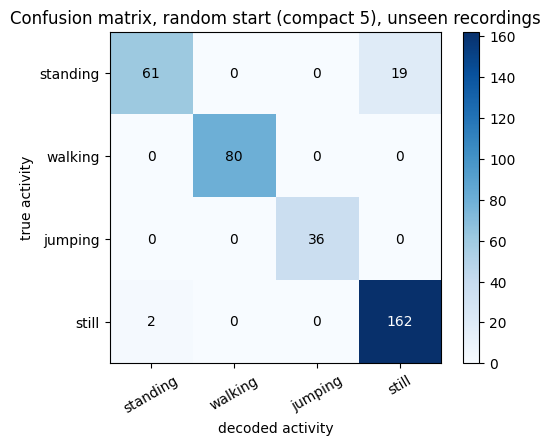

ok      5 random starts for each of the 2 feature sets
ok      every final log-likelihood is finite
ok      exactly one start chosen for each feature set
ok      every state to activity match is a valid shuffle of the 4 activities
ok      every start decodes all 360 test windows
ok      accuracies are between 0 and 1
all checks passed: True


In [21]:
random_rows, random_models = [], {}
for set_name in ["compact (5)", "all 14"]:
    cols = z_names(FEATURE_SETS[set_name])
    train_seq_r, test_seq_r = split_sequences(cols)
    for s in range(5):
        m = init_random(train_seq_r, SEED + s).fit(train_seq_r)
        truth, states = decode_sequences(m, train_seq_r)
        mp = best_mapping(confusion(states, truth))
        conf_t, _ = evaluate(m, test_seq_r, mp)
        random_models[(set_name, SEED + s)] = (m, mp, conf_t)
        random_rows.append({"features": set_name, "start seed": SEED + s, "rounds": len(m.history),
                            "converged": m.converged, "final train log-likelihood": m.history[-1],
                            "states used": len(np.unique(states)),
                            "state to activity": ", ".join(f"{i}:{ACTIVITIES[a]}" for i, a in enumerate(mp)),
                            "train accuracy": accuracy(confusion(truth, mp[states])),
                            "test accuracy": accuracy(conf_t), "_total": int(conf_t.sum()),
                            "_perm": sorted(mp.tolist()) == list(range(N_STATES))})

random_table = pd.DataFrame(random_rows)
random_table["chosen (best log-likelihood)"] = False
for set_name, part in random_table.groupby("features"):
    random_table.loc[part["final train log-likelihood"].idxmax(), "chosen (best log-likelihood)"] = True
random_table = random_table.set_index(["features", "start seed"])
display(random_table.drop(columns=["_total", "_perm"]).round(3))

for set_name, part in random_table.groupby("features"):
    print(set_name, "| different end points (log-likelihood to 1 decimal):",
          part["final train log-likelihood"].round(1).nunique(), "of", len(part))

best_key = random_table.loc["compact (5)"]["final train log-likelihood"].idxmax()
best_model, best_map, best_conf = random_models[("compact (5)", best_key)]
plot_confusion(best_conf, "Confusion matrix, random start (compact 5), unseen recordings", "confusion_test_random.png")

random_checks = [
    check("5 random starts for each of the 2 feature sets", len(random_table) == 10),
    check("every final log-likelihood is finite", np.isfinite(random_table["final train log-likelihood"]).all()),
    check("exactly one start chosen for each feature set", random_table.groupby("features")["chosen (best log-likelihood)"].sum().eq(1).all()),
    check("every state to activity match is a valid shuffle of the 4 activities", random_table["_perm"].all()),
    check("every start decodes all 360 test windows", (random_table["_total"] == 360).all()),
    check("accuracies are between 0 and 1", random_table[["train accuracy", "test accuracy"]].stack().between(0, 1).all()),
]
print("all checks passed:", all(random_checks))

**What the random start table shows.**

**Baum-Welch can find the activities without the labels, but only from some starts.** For the main feature set (compact 5), two of the five starts (seeds 44 and 46) reach a log-likelihood of -1401.284. Their state to activity match is a different shuffle of the 4 states, but the result is the same: 0.939 training accuracy, 0.942 test accuracy, and the same confusion matrix as the supervised start (61 and 19 for standing, 2 and 162 for still). The other three starts stop at much worse solutions (log-likelihood from -1486 to -2338, accuracy of 0.47 to 0.66). All of them used 4 states, so the problem is not an empty state but states that are matched to the wrong groups, for example two states sharing one activity and another state taking two. For all 14 features it is the same: the start with the highest log-likelihood (seed 42, -2820) gives 0.992 on training and on test, and the other four give 0.54 to 0.79 on test.

**The log-likelihood picked the right start both times.** Without labels I can only choose between starts with the log-likelihood, and the one with the highest value was also the most accurate one in both feature sets. I only had 5 starts, though, so I can not be sure that there is no better solution somewhere else. And since three of the five starts (compact) and four of the five (all 14) ended in clearly worse solutions, a single random start would often have given a bad model.

**What this says about Baum-Welch.** The solution with the best likelihood that I could find, from random starts, is the same one that the supervised start gave in section 8, with the standing to still flickering. So the loss in accuracy in section 8 is not a problem of the supervised start. The solution with the best likelihood is just not the solution with the best activity labels, because the model can raise the likelihood by letting the standing and still states share some windows.

### 12.3 Does the variance floor matter?

The variance floor stops a variance from going close to zero. In section 10 the floor (0.05, a standard deviation of 0.22) was used by every state for `log_energy_high` and by the still state for `zero_cross_rate` and `dominant_hz`, so it may be blurring the difference between standing and still. Here I try five floors on the main feature set (compact 5): 0.05 (the main model), 0.02, 0.01, 0.005 and 0.001. For each floor I train with Baum-Welch from the supervised start, and I also keep the start model without Baum-Welch.

A lower floor lets a state be very sure about a feature. That is good if the windows really are that similar, but it is risky for still windows that sit exactly at the floor of the log scale, because a tiny difference then counts as a big surprise. "Variances at the floor" counts how many of the 20 variances (4 states times 5 features) are stuck at the floor value after training. The main model stays at 0.05, and the test numbers are only for looking at what the floor does.

In [22]:
def init_with_floor(sequences, floor):
    base = init_supervised(sequences)
    X, y = stack_sequences(sequences)
    raw_var = np.stack([X[y == k].var(axis=0) for k in range(N_STATES)])
    return GaussianHMM(base.pi, base.A, base.means, raw_var, var_floor=floor)


FLOORS = [0.05, 0.02, 0.01, 0.005, 0.001]
train_f, test_f = split_sequences(z_names(FEATURE_SETS["compact (5)"]))

floor_rows, floor_ok = [], []
for floor in FLOORS:
    start_f = init_with_floor(train_f, floor)
    trained_f = init_with_floor(train_f, floor).fit(train_f)
    for label, mod in [("trained", trained_f), ("start", start_f)]:
        conf_t, table_t = evaluate(mod, test_f)
        truth_tr, pred_tr = decode_sequences(mod, train_f)
        truth_e, pred_e = emission_only(mod, None, test_f)
        floor_ok.append(bool((mod.variances >= floor - 1e-12).all()))
        floor_rows.append({"floor": floor, "model": label,
                           "rounds": len(mod.history) if label == "trained" else 0,
                           "converged": mod.converged if label == "trained" else None,
                           "variances at the floor": int(np.isclose(mod.variances, floor).sum()),
                           "train accuracy (Viterbi)": accuracy(confusion(truth_tr, pred_tr)),
                           "test accuracy (Viterbi)": accuracy(conf_t),
                           "test accuracy (emissions only)": accuracy(confusion(truth_e, pred_e)),
                           "test sensitivity standing": table_t.loc["standing", "sensitivity"],
                           "test specificity still": table_t.loc["still", "specificity"],
                           "_total": int(conf_t.sum())})

floor_table = pd.DataFrame(floor_rows).set_index(["floor", "model"])
display(floor_table.drop(columns="_total").round(3))

main_floor_row = floor_table.loc[(0.05, "trained")]
floor_checks = [
    check("5 floors for both models", len(floor_table) == 10),
    check("the 0.05 row matches the main model (test)", np.isclose(main_floor_row["test accuracy (Viterbi)"], accuracy(conf_main))),
    check("the 0.05 row matches the main model (train)", np.isclose(main_floor_row["train accuracy (Viterbi)"], accuracy(main["train_conf"]))),
    check("no variance is below its floor", all(floor_ok)),
    check("every row decodes all 360 test windows", (floor_table["_total"] == 360).all()),
    check("accuracies are between 0 and 1", floor_table[[c for c in floor_table.columns if "accuracy" in c]].stack().between(0, 1).all()),
]
print("all checks passed:", all(floor_checks))

rounds converged  variances at the floor  \
floor model                                               
0.050 trained      23      True                       6   
      start         0      None                       4   
0.020 trained      38      True                       3   
      start         0      None                       2   
0.010 trained      53      True                       2   
      start         0      None                       1   
0.005 trained      96      True                       1   
      start         0      None                       0   
0.001 trained      47      True                       1   
      start         0      None                       0   

               train accuracy (Viterbi)  test accuracy (Viterbi)  \
floor model                                                        
0.050 trained                     0.939                    0.942   
      start                       0.997                    1.000   
0.020 trained                     0.903                    0.908   
      start                       0.984                    1.000   
0.010 trained                     0.834                    0.864   
      start                       0.985                    0.989   
0.005 trained                     0.821                    0.850   
      start                       0.985                    0.989   
0.001 trained                     0.821                    0.828   
      start                       0.985                    0.989   

               test accuracy (emissions only)  test sensitivity standing  \
floor model                                                                
0.050 trained                           0.892                      0.762   
      start                             0.883                      1.000   
0.020 trained                           0.892                      0.662   
      start                             0.894                      1.000   
0.010 trained                           0.867                      0.438   
      start                             0.900                      1.000   
0.005 trained                           0.850                      0.388   
      start                             0.900                      1.000   
0.001 trained                           0.831                      0.362   
      start                             0.900                      1.000   

               test specificity still  
floor model                            
0.050 trained                   0.903  
      start                     1.000  
0.020 trained                   0.862  
      start                     1.000  
0.010 trained                   0.770  
      start                     1.000  
0.005 trained                   0.750  
      start                     1.000  
0.001 trained                   0.740  
      start                     1.000

ok      5 floors for both models
ok      the 0.05 row matches the main model (test)
ok      the 0.05 row matches the main model (train)
ok      no variance is below its floor
ok      every row decodes all 360 test windows
ok      accuracies are between 0 and 1
all checks passed: True


**What the variance floor table shows.**

**A smaller floor did not help the trained model.** As the floor goes from 0.05 down to 0.001, the test accuracy of the trained model falls from 0.942 to 0.828, the training accuracy falls from 0.939 to 0.821, and the sensitivity of standing falls from 0.762 to 0.362. In section 10 I thought that the floor was blurring the difference between standing and still, and that a lower floor would help. This is not supported, at least for Baum-Welch. I did not test why it gets worse. The training also needs more rounds with a smaller floor (23 rounds at 0.05, 96 at 0.005), but all of them stop because of epsilon.

**For the start model the floor matters much less.** Its accuracy for single windows (emissions only) goes up a little when the floor is lower (0.883 at 0.05, 0.894 at 0.02 and 0.900 at 0.01 or lower). This is about 6 windows out of 360, which is small for such a small test set, so I do not read much into it. The accuracy with Viterbi goes from 1.000 (floor 0.05 and 0.02) to 0.989 (floor 0.01 and lower), and the training accuracy goes from 0.997 to 0.985. So here a lower floor is a bit worse with transitions and a bit better without them.

**How many variances are stuck at the floor.** For the trained model, 6 of the 20 variances sit at the floor of 0.05, 3 at 0.02, 2 at 0.01 and only 1 at 0.005 and 0.001. For the start model there are none at 0.005 or below. So the real spread of most features is larger than 0.005, and a floor of 0.05 only limits a few of them (the ones I saw in section 10).

**What I keep.** The floor stays at 0.05 for the main model. The idea that the floor hides a better separation between standing and still did not work out in these tests. I only tried one feature set, with the supervised start, so this is not a general statement about floors.

# 13. Reflection

### 13.1 Which activities were easy and which were hard

**Jumping and walking were the easiest.** In the main model and in the start model, every jumping and walking window in the test recordings was decoded correctly (sensitivity and specificity of 1.000), both alone and in the glued sequence. The reason is in the emission plots: jumping has a much higher movement strength (`log_energy_high`) and a high correlation between the axes (`corr_xz`), and walking has a clear rhythm and a higher spectral entropy. Their curves are far from the other states.

**Standing and still were the hardest, and they are the only pair that got mixed up.** Both are low-movement activities, so their features sit close to each other. Judged one window at a time (emissions only), only 64% to 70% of the standing windows were found, and about 25 to 29 of the 80 windows of standing2 looked more like still. The feature that separated the two best was `zero_cross_rate`, and the one that helped the least was `spectral_entropy`. The orientation features separated them very well (accuracy 1.000 in the set with orientation), but I think this is partly a shortcut, because in my recordings still always has the phone lying flat and standing always has it held tilted. I did not test a case where this is not true.

**Training and test were similar.** The mistakes were in the same pair on the training recordings and on the unseen ones, so the problem is in the features, not in a lucky or unlucky split.

### 13.2 Are the learned transitions realistic?

**Not really, and the reason is the data.** Every recording has only one activity, so the training data has no real change from one activity to another. The transition matrix can only learn "stay". Before Baum-Welch the matrix is almost the identity (0.99 for staying), and the small numbers outside the diagonal come from the pseudo count and not from the data.

After Baum-Welch the matrix has a standing to still probability of 0.102 and a still to standing probability of 0.082. This is not something I measured about people. Baum-Welch moved some windows between the two states, and this was counted as moves. It also gives a wrong idea of how long an activity lasts: a stay probability of 0.89 or 0.91 means about 9 to 11 windows, while my standing and still recordings are 60 to 164 windows long. The decoded sequences show the result. The trained model switches 17 times on the glued sequence where there are 3 real switches, and it flickers between standing and still for 2 to 4 windows at a time, which no person does. The start model, with its almost-never-switching matrix, makes 3 switches, like the real sequence.

A realistic matrix would need recordings where the activity really changes (for example walking, then stopping, then standing), so that moves like walking to standing can be counted. My glued sequence can show that Viterbi follows a switch, but its switches are sudden (one recording ends and another begins), so it is easier than a real change. The 1 second step between windows is not always the same either: it is 2 seconds across the edge of a clip.

### 13.3 Noise and sampling rate

I did not run an experiment on these two. What follows is what I know from the data and what I expect.

**Sampling rate.** I asked the app for 50 Hz, but the phone gave about 27.5 Hz (one sample every 36 ms), and it was steady. I converted every clip to an even 25 Hz grid with linear interpolation. This keeps frequencies up to 12.5 Hz. Walking and jumping repeat at about 1.5 to 2.6 times per second, so their rhythm is well inside this range. The features that use the part above 3 Hz (`log_energy_high`) can only see up to 12.5 Hz, and the sharp hit when landing from a jump probably has energy above that. The linear interpolation also smooths the signal a little. A faster rate would give a better view of these hits and of small shaking. With a window of 2 seconds the real frequency step of the FFT is 0.5 Hz, so `dominant_hz` can not tell 1.5 from 1.8 Hz well. The zero padding only makes the picture smoother.

**Noise.** The still recordings have a standard deviation of about 0.001 in the movement, and the log features of these windows sit at the floor I put in (0.0001 before the log). So what the model sees for still is mostly the noise level of the phone's sensor and the floor, and many still windows look alike. That is why the variance of some still features sits at the variance floor. For standing, the small movements of my hand and body are the noise, and this is the part that looks like still. If the noise were higher, for example with a cheaper sensor or a phone in a loose pocket, I expect standing and still to be mixed up even more, because they differ only by a small amount. Walking and jumping are well above the noise, so I expect them to stay stable.

### 13.4 What I would improve

- **Recordings with real changes of activity.** This is the biggest one. With sequences that really go from one activity to another, the transition matrix can be learned from data, and the test would show real switches and not glued ones.
- **More recordings of walking and still.** There is only one training recording and one test recording for each. Because of this I could not use cross-validation to choose the feature set, since leaving one out removes the whole activity. The test result is also only four recordings, from one person and one phone.
- **More ways of holding the phone, more people and more phones.** In my data still is always flat and standing is always tilted. A model that works for other people has to be tested where this is not true, for example standing still with the phone in the hand, or sitting with the phone in the pocket.
- **A better training method than plain Baum-Welch.** Baum-Welch raised the likelihood but lowered the accuracy in every feature set I tried. Ways to avoid this are to use the labels in the E step, or to fix or limit the transition matrix, so that standing and still can not share windows so easily.
- **Stop the flickering.** A model with a minimum time in a state (a hidden semi-Markov model), or a smoothing step after Viterbi, would remove the 2 to 4 window jumps.
- **A better emission model.** A mixture of Gaussians for each state, or fewer repeated features, would make the emissions less sure of themselves. The feature set with orientation was the best, and I would like to know if it still works when the phone position changes.
- **A gyroscope.** My phones do not have one. It would add the turning movement of the body, which is useful for telling walking from standing.
- **Faster sampling.** 50 Hz or more would show the sharp hits in jumping better.

# 14. Summary of the results

The last cell collects the main results in one table and saves it, and lists the figures and tables that the notebook saved, so that I can put them in the repository and the report. The main model is the trained model with 5 features (compact 5). The start model without Baum-Welch is the comparison.

In [23]:
final_rows = []
for label, table, conf in [("trained model (main)", table_main, conf_main),
                           ("start model (no Baum-Welch)", table_start, conf_start)]:
    final_rows.append({"model": label, "overall accuracy": accuracy(conf),
                       **{f"sensitivity {a}": table.loc[a, "sensitivity"] for a in ACTIVITIES},
                       **{f"specificity {a}": table.loc[a, "specificity"] for a in ACTIVITIES}})
final_table = pd.DataFrame(final_rows).set_index("model")
final_table.to_csv(OUT_ROOT / "hmm_final_results.csv")
display(final_table.round(3).T)

expected_figures = ["loglik_curve.png", "confusion_test.png", "confusion_test_start.png", "confusion_test_random.png",
                    "transition_heatmap.png", "emissions.png", "decoded_glued.png", "decoded_each_test_recording.png"]
expected_tables = ["hmm_feature_sets.csv", "hmm_final_results.csv"]
print("figures saved:", sorted(p.name for p in FIG_DIR.glob("*.png")))
print("tables saved :", sorted(p.name for p in OUT_ROOT.glob("hmm_*.csv")))

final_checks = [
    check("the final table has the two models", len(final_table) == 2),
    check("main model accuracy matches section 9", np.isclose(final_table.loc["trained model (main)", "overall accuracy"], accuracy(conf_main))),
    check("every sensitivity and specificity is between 0 and 1", final_table.drop(columns="overall accuracy").stack().between(0, 1).all()),
    check("all expected figures were saved", all((FIG_DIR / f).exists() for f in expected_figures)),
    check("all expected tables were saved", all((OUT_ROOT / f).exists() for f in expected_tables)),
]
print("all checks passed:", all(final_checks))

model,trained model (main),start model (no Baum-Welch)
overall accuracy,0.942,1.0
sensitivity standing,0.762,1.0
sensitivity walking,1.000,1.0
sensitivity jumping,1.000,1.0
sensitivity still,0.988,1.0
specificity standing,0.993,1.0
specificity walking,1.000,1.0
specificity jumping,1.000,1.0
specificity still,0.903,1.0


figures saved: ['confusion_test.png', 'confusion_test_random.png', 'confusion_test_start.png', 'decoded_each_test_recording.png', 'decoded_glued.png', 'emissions.png', 'loglik_curve.png', 'transition_heatmap.png']
tables saved : ['hmm_feature_sets.csv', 'hmm_final_results.csv']
ok      the final table has the two models
ok      main model accuracy matches section 9
ok      every sensitivity and specificity is between 0 and 1
ok      all expected figures were saved
ok      all expected tables were saved
all checks passed: True


# 15. Sample signals for the report

One 5 second clip of each activity from the saved dataset. For each activity I take the training clip whose shakiness is closest to the middle for that activity, so the plot shows a normal clip and not the best or worst one. This is a bigger version of the raw signal plot in the data notebook, made for the report.

ok      one manifest.csv found in the inputs


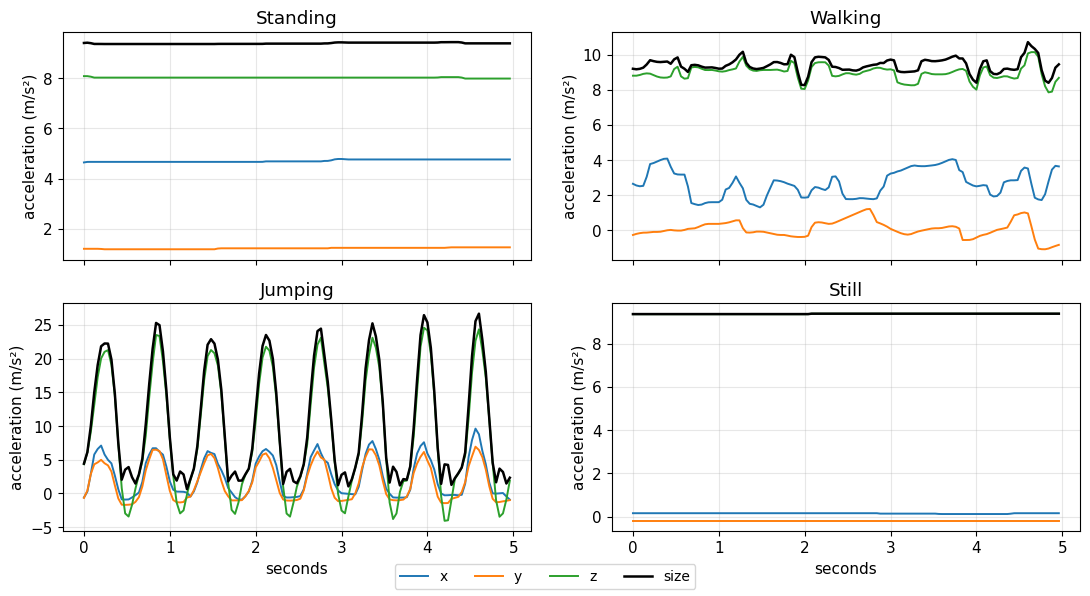

{'standing': 'standing_038.csv', 'walking': 'walking_012.csv', 'jumping': 'jumping_014.csv', 'still': 'still_007.csv'}
ok      one clip picked for each activity
ok      every picked clip has 125 samples
ok      figure file was saved
all checks passed: True


In [27]:
manifest_paths = sorted(Path("/kaggle/input").rglob("manifest.csv"))
sample_results = []
def sample_check(name, passed):
    sample_results.append(bool(passed))
    print("ok     " if passed else "FAILED", name)

sample_check("one manifest.csv found in the inputs", len(manifest_paths) == 1)
CLIP_DIR = manifest_paths[0].parent
clip_manifest = pd.read_csv(manifest_paths[0])
SENSOR = ["acc_x", "acc_y", "acc_z"]
SAMPLE_ACTIVITIES = ["standing", "walking", "jumping", "still"]

plt.rcParams.update({"font.size": 11})
picked = {}
for activity in SAMPLE_ACTIVITIES:
    rows = clip_manifest[(clip_manifest["activity"] == activity) & (clip_manifest["split"] == "train")]
    spreads = np.array([np.sqrt((pd.read_csv(CLIP_DIR / f)[SENSOR].values ** 2).sum(axis=1)).std() for f in rows["file"]])
    picked[activity] = rows.iloc[int(np.argmin(np.abs(spreads - np.median(spreads))))]["file"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, activity in zip(axes.ravel(), SAMPLE_ACTIVITIES):
    clip = pd.read_csv(CLIP_DIR / picked[activity])
    for col, label in zip(SENSOR, ["x", "y", "z"]):
        ax.plot(clip["timestamp"], clip[col], label=label, linewidth=1.4)
    ax.plot(clip["timestamp"], np.sqrt((clip[SENSOR].values ** 2).sum(axis=1)),
            color="black", linewidth=1.8, label="size")
    ax.set_title(activity.capitalize())
    ax.set_ylabel("acceleration (m/s²)")
    ax.grid(True, alpha=0.3)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=10)
axes[1, 0].set_xlabel("seconds")
axes[1, 1].set_xlabel("seconds")
plt.tight_layout()
plt.savefig("raw_signals_report.png", dpi=200)
plt.show()

print({a: Path(f).name for a, f in picked.items()})
sample_check("one clip picked for each activity", len(picked) == 4)
sample_check("every picked clip has 125 samples", all(len(pd.read_csv(CLIP_DIR / f)) == 125 for f in picked.values()))
sample_check("figure file was saved", Path("raw_signals_report.png").exists())
print("all checks passed:", all(sample_results))

In [26]:
import inspect

for fn in [build_sequences, split_sequences, decode_sequences, evaluate, accuracy]:
    print(inspect.getsource(fn))
    print("-" * 60)

print("main_features:", main_features)
print("data columns:", list(data.columns))
print("test_seq keys:", list(test_seq.keys()))
first_key = list(test_seq.keys())[0]
first = test_seq[first_key]
print("test_seq value type:", type(first).__name__)
if isinstance(first, (tuple, list)):
    print([getattr(v, "shape", type(v).__name__) for v in first])
print("mapping:", mapping)
print(data.head(3).to_string())

def build_sequences(frame, columns):
    sequences = {}
    for name, part in frame.groupby("recording"):
        part = part.sort_values("start_s")
        sequences[name] = (part[columns].to_numpy(float), part["state"].to_numpy(int))
    return sequences

------------------------------------------------------------
def split_sequences(columns):
    train = build_sequences(data[data["split"] == "train"], columns)
    test = build_sequences(data[data["split"] == "test"], columns)
    return train, test

------------------------------------------------------------
def decode_sequences(model, sequences, mapping=None):
    """Decode every sequence. Returns the true and the decoded labels as two long arrays. A mapping renames the states to activities."""
    truth, pred = [], []
    for X, y in sequences.values():
        path, _ = model.decode(X)
        truth.append(y)
        pred.append(path if mapping is None else mapping[path])
    return np.concatenate(truth), np.concatenate(pred)



# 16. Noise and sampling rate on the unseen recordings

So far the test clips were used as they are. Here I damage the test clips in two ways and decode them with the same trained models, without any retraining: Gaussian noise added to the raw signal, and a lower sampling rate (12.5 Hz, every second sample). Every feature is computed again from the damaged clips with the same feature code as the data notebook and normalised with the training numbers. The first step only checks that this rebuilt path gives back exactly the numbers from section 9, so any change later comes from the damage and not from the rebuilding.

In [28]:
nb_paths = sorted(Path("/kaggle/input").rglob("__notebook__.ipynb"))
data_nb = json.loads(nb_paths[0].read_text())
feat_src = None
for nb_cell in data_nb["cells"]:
    src = "".join(nb_cell["source"])
    if nb_cell["cell_type"] == "code" and "def window_features" in src:
        feat_src = src.split("features = pd.DataFrame(")[0]
exp_ns = {"np": np, "pd": pd, "fft": np.fft.fft, "fftfreq": np.fft.fftfreq}
exec(feat_src, exp_ns)
window_features = exp_ns["window_features"]
FEATURE_NAMES = exp_ns["FEATURE_NAMES"]

feat_paths = sorted(Path("/kaggle/input").rglob("features.csv"))
feature_table = pd.read_csv(feat_paths[0])
train_raw = feature_table[feature_table["split"] == "train"][FEATURE_NAMES]
feat_mean = train_raw.mean()
feat_std = train_raw.std(ddof=0).replace(0, 1.0)

test_rows = data[data["split"] == "test"].copy()
test_rows["k"] = test_rows.groupby("clip_file")["start_s"].rank(method="first").astype(int) - 1
Z_COLS = ["z_" + f for f in main_features]

def make_z(perturb=None, hz=25, win=50, step=25, seed=0):
    rng = np.random.default_rng(seed)
    clips = {}
    out = np.zeros((len(test_rows), len(FEATURE_NAMES)))
    for i, (f, k) in enumerate(zip(test_rows["clip_file"], test_rows["k"])):
        if f not in clips:
            values = pd.read_csv(CLIP_DIR / f)[SENSOR].to_numpy(float)
            clips[f] = values if perturb is None else perturb(values, rng)
        w = clips[f][k * step: k * step + win]
        out[i] = (np.array(window_features(w, hz)) - feat_mean.values) / feat_std.values
    return pd.DataFrame(out, columns=["z_" + n for n in FEATURE_NAMES], index=test_rows.index)

def score(model_obj, z_frame):
    frame = test_rows.copy()
    frame[Z_COLS] = z_frame[Z_COLS]
    conf_x, table_x = evaluate(model_obj, build_sequences(frame, Z_COLS))
    return accuracy(conf_x), conf_x, table_x

z_clean = make_z()
acc_main_clean, conf_main_clean, _ = score(model, z_clean)
acc_start_clean, conf_start_clean, _ = score(start_model, z_clean)

print("clean run, main model :", round(acc_main_clean, 4))
print("clean run, start model:", round(acc_start_clean, 4))

exp_results = []
def exp_check(name, passed):
    exp_results.append(bool(passed))
    print("ok     " if passed else "FAILED", name)

exp_check("feature code was found in the data notebook", feat_src is not None)
exp_check("features.csv has all 14 features and a split column",
          all(n in feature_table.columns for n in FEATURE_NAMES) and "split" in feature_table.columns)
exp_check("360 test windows, 4 per clip", len(test_rows) == 360 and test_rows["k"].max() == 3)
exp_check("rebuilt z-scores equal the saved ones",
          float(np.abs(z_clean[["z_" + n for n in FEATURE_NAMES]].values
                       - test_rows[["z_" + n for n in FEATURE_NAMES]].values).max()) < 1e-6)
exp_check("main model clean accuracy matches section 9", abs(acc_main_clean - accuracy(conf_main)) < 1e-12)
exp_check("start model clean accuracy matches section 9", abs(acc_start_clean - accuracy(conf_start)) < 1e-12)
print("all checks passed:", all(exp_results))

clean run, main model : 0.9417
clean run, start model: 1.0
ok      feature code was found in the data notebook
ok      features.csv has all 14 features and a split column
ok      360 test windows, 4 per clip
ok      rebuilt z-scores equal the saved ones
ok      main model clean accuracy matches section 9
ok      start model clean accuracy matches section 9
all checks passed: True


In [30]:
SIGMAS = [0.0, 0.05, 0.1, 0.25, 0.5, 1.0]
SEEDS = [0, 1, 2, 3, 4]

def add_noise(sigma):
    return lambda values, rng: values + rng.normal(0.0, sigma, values.shape)

def halve(values, rng):
    return values[::2]

size_spread = {}
for activity in ACTIVITIES:
    files = clip_manifest[(clip_manifest["split"] == "test") & (clip_manifest["activity"] == activity)]["file"]
    size_spread[activity] = float(np.median([
        np.sqrt((pd.read_csv(CLIP_DIR / f)[SENSOR].to_numpy(float) ** 2).sum(axis=1)).std() for f in files]))
print("typical spread of the signal size in the test clips (m/s²):",
      {a: round(v, 3) for a, v in size_spread.items()})

noise_rows = []
for sigma in SIGMAS:
    accs = {"main": [], "start": []}
    for seed in SEEDS:
        z_noisy = make_z(add_noise(sigma), seed=seed)
        accs["main"].append(score(model, z_noisy)[0])
        accs["start"].append(score(start_model, z_noisy)[0])
    noise_rows.append({
        "noise std (m/s²)": sigma,
        "main mean": np.mean(accs["main"]), "main min": np.min(accs["main"]), "main max": np.max(accs["main"]),
        "start mean": np.mean(accs["start"]), "start min": np.min(accs["start"]), "start max": np.max(accs["start"]),
    })
noise_table = pd.DataFrame(noise_rows).round(4)
print("\nGaussian noise added to the raw test clips (5 random draws per level)")
print(noise_table.to_string(index=False))

z_half = make_z(halve, hz=12.5, win=25, step=12)
half_rows = []
for name, mdl in [("main", model), ("start", start_model)]:
    acc_h, conf_h, table_h = score(mdl, z_half)
    row = {"model": name, "accuracy": round(acc_h, 4)}
    row.update({f"sens {a}": round(float(s), 3) for a, s in table_h["sensitivity"].items()})
    half_rows.append(row)
half_table = pd.DataFrame(half_rows)
print("\nTest clips down-sampled from 25 Hz to 12.5 Hz (every second sample)")
print(half_table.to_string(index=False))

noise_table.to_csv("noise_results.csv", index=False)
half_table.to_csv("sampling_rate_results.csv", index=False)

exp_results = []
exp_check("zero noise gives back the clean accuracy for both models",
          abs(noise_table.loc[0, "main mean"] - round(acc_main_clean, 4)) < 1e-9
          and abs(noise_table.loc[0, "start mean"] - round(acc_start_clean, 4)) < 1e-9)
exp_check("every accuracy is between 0 and 1",
          bool(((noise_table.iloc[:, 1:] >= 0) & (noise_table.iloc[:, 1:] <= 1)).all().all()
               and (half_table["accuracy"].between(0, 1)).all()))
exp_check("no missing values in the 12.5 Hz features", not z_half.isna().any().any())
exp_check("6 noise levels and 2 models at 12.5 Hz", len(noise_table) == 6 and len(half_table) == 2)
exp_check("result files were saved", Path("noise_results.csv").exists() and Path("sampling_rate_results.csv").exists())
print("all checks passed:", all(exp_results))

typical spread of the signal size in the test clips (m/s²): {'standing': 0.022, 'walking': 1.063, 'jumping': 8.632, 'still': 0.01}

Gaussian noise added to the raw test clips (5 random draws per level)
 noise std (m/s²)  main mean  main min  main max  start mean  start min  start max
             0.00     0.9417    0.9417    0.9417      1.0000     1.0000     1.0000
             0.05     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222
             0.10     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222
             0.25     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222
             0.50     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222
             1.00     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222

Test clips down-sampled from 25 Hz to 12.5 Hz (every second sample)
model  accuracy  sens standing  sens walking  sens jumping  sens still
 main    0.9167          0.675           1.0         0.889         1.0
start 

In [31]:
SIGMAS_FINE = [0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.05]

fine_rows = []
for sigma in SIGMAS_FINE:
    accs = {"main": [], "start": []}
    for seed in SEEDS:
        z_noisy = make_z(add_noise(sigma), seed=seed)
        accs["main"].append(score(model, z_noisy)[0])
        accs["start"].append(score(start_model, z_noisy)[0])
    fine_rows.append({
        "noise std (m/s²)": sigma,
        "main mean": np.mean(accs["main"]), "main min": np.min(accs["main"]), "main max": np.max(accs["main"]),
        "start mean": np.mean(accs["start"]), "start min": np.min(accs["start"]), "start max": np.max(accs["start"]),
    })
fine_table = pd.DataFrame(fine_rows).round(4)
print("Gaussian noise added to the raw test clips, small levels (5 random draws each)")
print("signal spread for comparison: still 0.010, standing 0.022, walking 1.063, jumping 8.632 m/s²")
print(fine_table.to_string(index=False))

z_probe = make_z(add_noise(0.05), seed=0)
for name, mdl in [("main", model), ("start", start_model)]:
    _, conf_probe, _ = score(mdl, z_probe)
    print(f"\nconfusion matrix at noise 0.05, {name} model (rows true, columns decoded)")
    print(pd.DataFrame(conf_probe, index=ACTIVITIES, columns=ACTIVITIES).to_string())

fine_table.to_csv("noise_results_small.csv", index=False)

exp_results = []
exp_check("7 small noise levels", len(fine_table) == 7)
exp_check("every accuracy is between 0 and 1",
          bool(((fine_table.iloc[:, 1:] >= 0) & (fine_table.iloc[:, 1:] <= 1)).all().all()))
exp_check("the 0.05 row matches the earlier run (0.3222)",
          abs(fine_table.loc[fine_table["noise std (m/s²)"] == 0.05, "main mean"].iloc[0] - 0.3222) < 1e-4)
exp_check("result file was saved", Path("noise_results_small.csv").exists())
print("all checks passed:", all(exp_results))

Gaussian noise added to the raw test clips, small levels (5 random draws each)
signal spread for comparison: still 0.010, standing 0.022, walking 1.063, jumping 8.632 m/s²
 noise std (m/s²)  main mean  main min  main max  start mean  start min  start max
            0.001     0.6928    0.6861    0.6972      0.6417     0.6306     0.6500
            0.002     0.6594    0.6417    0.6750      0.5994     0.5861     0.6139
            0.005     0.5550    0.5500    0.5583      0.5450     0.5361     0.5556
            0.010     0.5167    0.5056    0.5278      0.5128     0.5056     0.5278
            0.020     0.3567    0.3417    0.3833      0.3278     0.3222     0.3333
            0.030     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222
            0.050     0.3222    0.3222    0.3222      0.3222     0.3222     0.3222

confusion matrix at noise 0.05, main model (rows true, columns decoded)
          standing  walking  jumping  still
standing         0       80        0      0
wal

### 16.1 What the noise and sampling rate results show

The first line of the check passed: with no change, the rebuilt path gives 0.9417 for the main model and 1.000 for the start model, the same as section 9.

**Sampling rate.** Keeping every second sample (12.5 Hz) costs a little. The main model goes from 0.942 to 0.917 and the start model from 1.000 to 0.989. Jumping loses 4 of its 36 windows in both models (sensitivity 0.889), and standing drops from 0.762 to 0.675 for the main model. Walking and still stay at 1.000.

**Noise.** Noise hurts much more. Accuracy is already about 0.69 (main) and 0.64 (start) at a noise of 0.001 m/s², and it is 0.32 for both models from 0.03 m/s² upwards. At 0.05 the confusion matrix shows that every standing and every still window is decoded as walking, while walking and jumping stay correct. The signal of standing and still is almost flat in my test clips (a spread of 0.022 and 0.010 m/s²), so the features of these two activities are tiny energies close to the floor of 1e-4. A small amount of noise lifts them to the level of walking. I did not test this reason directly, but it fits the numbers and the feature box plots.

**What it means.** The model works because the sensor of this phone is very clean. The noise used here is artificial white noise, so it may be harsher than the real noise of a phone, but it shows that the features of standing and still are not robust. Filtering the signal before the features, or training on noisy copies of the clips, are the first things I would try.